<a href="https://colab.research.google.com/github/Hanklin999/26Fall_95896_Python/blob/main/assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Read in the appropriate packages

In [ ]:
#conda install -c conda-forge frozendict
#conda install -c conda-forge yfinance

In [ ]:
from pandas_datareader import data as pdr #read data from yahoo finance api
import yfinance as yf
import matplotlib.pyplot as plt #viz #GUI manager
import seaborn as sns #viz #plotly is another package
import datetime
import pandas as pd
import numpy as np
from pandas import Grouper #groupby
#statistical data exploration, conducting statistical tests, and estimation of different statistical models
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf #autocorrelation plot
from statsmodels.tsa.api import SimpleExpSmoothing
from statsmodels.tsa.holtwinters import ExponentialSmoothing # double and triple exponential smoothing
from pandas.plotting import autocorrelation_plot #autocorrelation plot
from statsmodels.graphics.gofplots import qqplot #residual diagnostics
from sklearn.metrics import mean_squared_error #accuracy metrics
from math import sqrt
from sklearn.metrics import mean_absolute_error #accuracy metrics

from random import gauss #create gaussian white noise
from random import seed
from pandas import Series


## White Noise

White noise is an important concept in time series forecasting. It is important for two main reasons:
1. Predictability: If your time series is white noise, then, by definition, it is random. You cannot reasonably model it and make predictions.
2. Model Diagnostics: The series of errors from a time series forecast model should ideally be white noise.

Model Diagnostics is an important area of time series forecasting.

Time series data are expected to contain some white noise component on top of the signal generated by the underlying process.

y(t) = signal(t) + noise(t)

Once predictions have been made by a time series forecast model, they can be collected and analyzed. The series of forecast errors should ideally be white noise.

When forecast errors are white noise, it means that all of the signal information in the time series has been harnessed by the model in order to make predictions. All that is left is the random fluctuations that cannot be modeled.

A sign that model predictions are not white noise is an indication that further improvements to the forecast model may be possible.

How to know if a time series is white noise or not? A time series is probably NOT white noise if one or more of the following conditions are true:

1. Is the mean/level non-zero?
2. Does the mean/level change over time? (does it have trend)
3. Does the variance change over time?
4. Do values correlate with lag values?

Some tools that you can use to check if your time series is white noise are:

1. Create a line plot. Check for gross features like a changing mean, variance, or obvious relationship between lagged variables.
2. Calculate summary statistics. Check the mean and variance.
3. Create an autocorrelation plot. Check for gross correlation between lagged variables.

Let us create a Gaussian white noise series and perform some checks.

It is helpful to create and review a white noise time series in practice. It will provide the frame of reference and example plots and statistical tests to use and compare on your own time series projects to check if they are white noise.

Source: https://machinelearningmastery.com/white-noise-time-series-python/

In [ ]:
# First, we can create a list of 1,000 random Gaussian variables using the gauss() function from the random module.
# We will draw variables from a Gaussian distribution with a mean (mu) of 0.0 and a standard deviation (sigma) of 1.0.
# Once created, we can wrap the list in a Pandas Series for convenience.

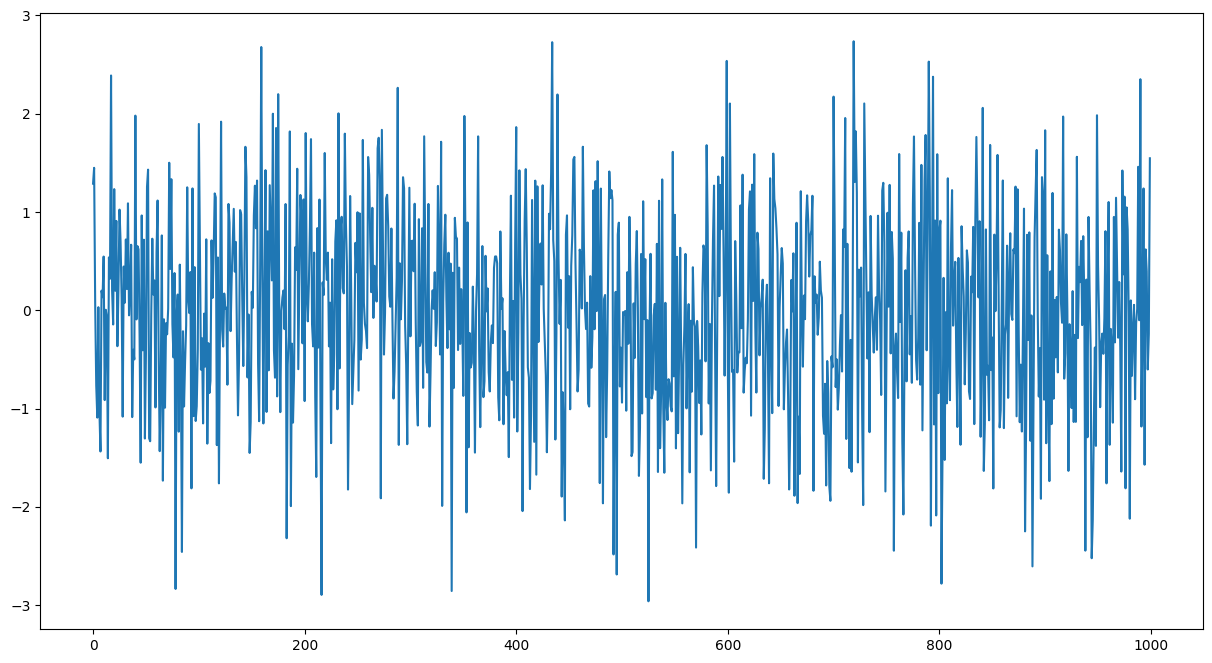

In [ ]:
# seed random number generator
seed(1)
# create white noise series
series = [gauss(0.0, 1.0) for i in range(1000)]
series = Series(series)

# line plot
plt.figure(figsize=(15,8))
series.plot()
plt.show()

In [ ]:
# Next, we can calculate and print some summary statistics, including the mean and standard deviation of the series.

# summary stats
series.describe()

,0
count,1000.000000
mean,-0.013222
std,1.003685
min,-2.961214
25%,-0.684192
50%,-0.010934
75%,0.703915
max,2.737260


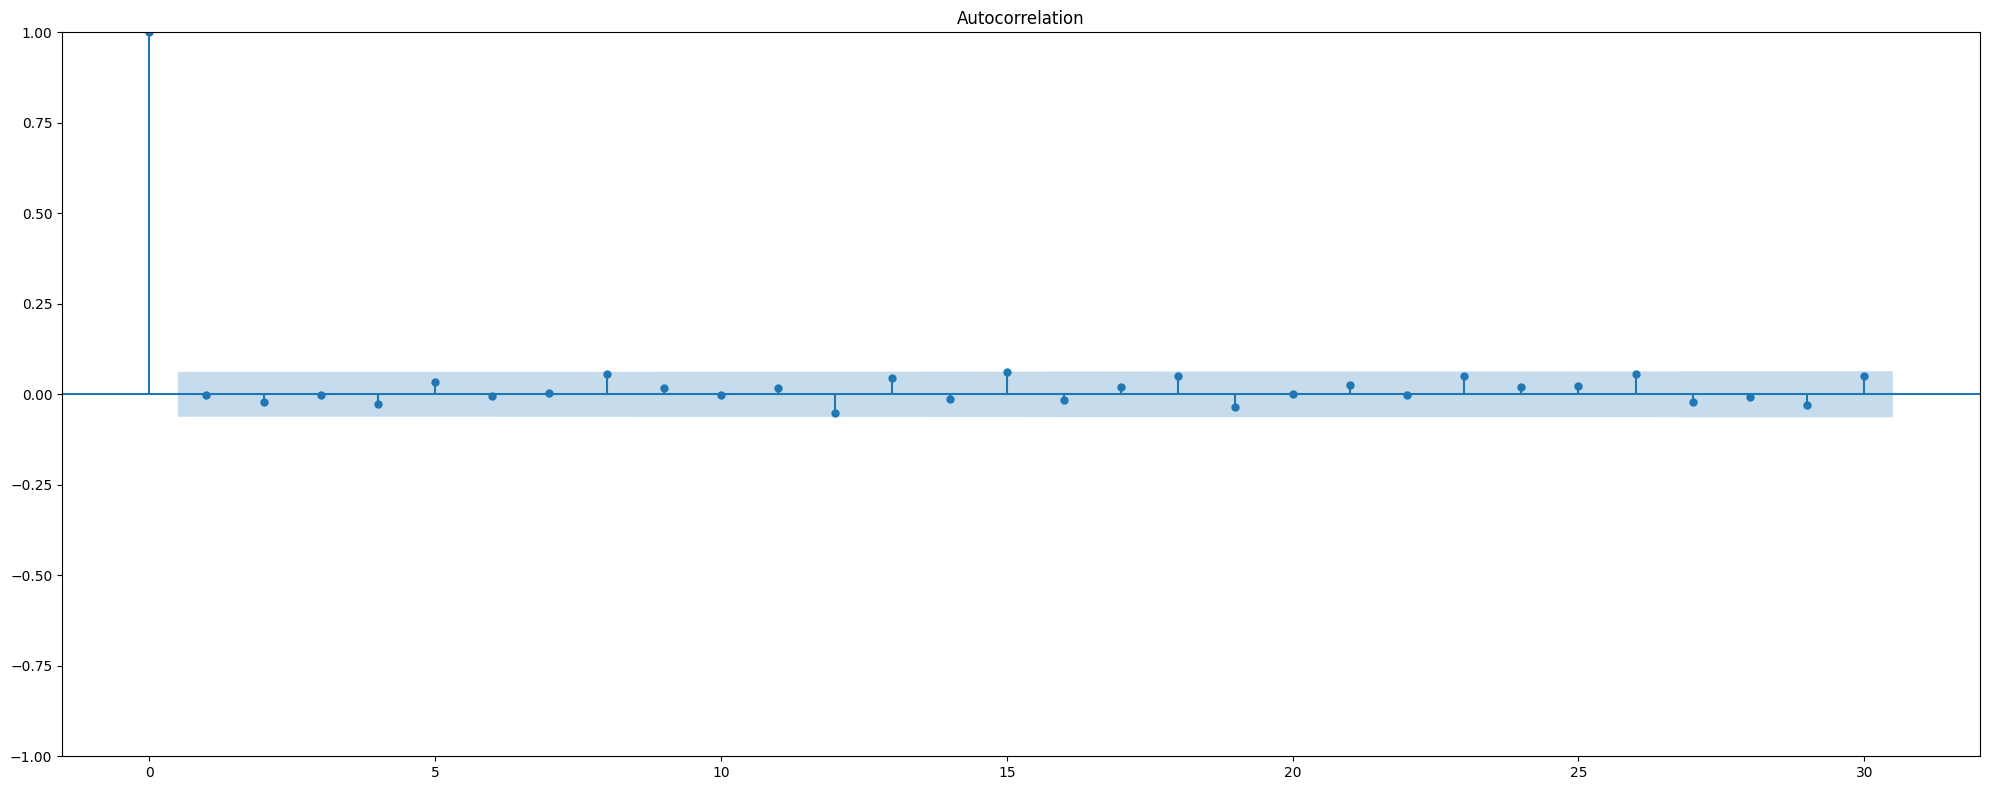

In [ ]:
# autocorrelation plot - see slides

fig = plot_acf(series, lags=30) #print only 30 lags
fig.set_size_inches((20,8))
# Tight layout to realign things
fig.tight_layout()
plt.show()

In summary:

1. White noise time series is defined by a zero mean, constant variance, and zero correlation.
2. If your time series is white noise, it cannot be predicted, and if your forecast residuals are not white noise, you may be able to improve your model.
3. Descriptive statistics and plots such as autocorrelation, line plots, and residual plots can be used on your time series to check if it is white noise.

## 1. Download stock data - single and multiple and get it into the right format

A way of getting the historical stock data is to use the pandas_datareader library.
It uses Yahoo’s Finance API to load in the data.

### First, download SINGLE stock using pandas_datareader

In [ ]:
# Define stock ticker and date range
stock_ticker = 'MSFT'
stock_start_date = datetime.date(2013,12,29)
stock_end_date = datetime.date.today()

# Fetch the stock price from Yahoo Finance using yfinance
stock_df = yf.download(stock_ticker, start=stock_start_date, end=stock_end_date)

/tmp/ipykernel_3270/3544724450.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_df = yf.download(stock_ticker, start=stock_start_date, end=stock_end_date)
[*********************100%***********************]  1 of 1 completed


In [ ]:
stock_df

Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2013-12-30,30.743948,30.818149,30.422411,30.686236,16290500
2013-12-31,30.842873,30.983032,30.686227,30.834629,17503500
2014-01-02,30.636778,30.834649,30.587309,30.793423,30632200
2014-01-03,30.430649,30.686231,30.175066,30.669742,31134800
2014-01-06,29.787580,30.414165,29.771091,30.381186,43603700
...,...,...,...,...,...
2026-08-26,496.369995,497.399994,487.309998,487.850006,20758900
2026-08-27,505.059998,506.480011,490.079987,494.880005,28688800


In [ ]:
stock_df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3187 entries, 2013-12-30 to 2026-09-01
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   (Close, MSFT)   3187 non-null   float64
 1   (High, MSFT)    3187 non-null   float64
 2   (Low, MSFT)     3187 non-null   float64
 3   (Open, MSFT)    3187 non-null   float64
 4   (Volume, MSFT)  3187 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 149.4 KB


In [ ]:
stock_df.index

DatetimeIndex(['2013-12-30', '2013-12-31', '2014-01-02', '2014-01-03',
               '2014-01-06', '2014-01-07', '2014-01-08', '2014-01-09',
               '2014-01-10', '2014-01-13',
               ...
               '2026-08-19', '2026-08-20', '2026-08-21', '2026-08-24',
               '2026-08-25', '2026-08-26', '2026-08-27', '2026-08-28',
               '2026-08-31', '2026-09-01'],
              dtype='datetime64[ns]', name='Date', length=3187, freq=None)

In [ ]:
# delete 2013 values
stock_df=stock_df[(stock_df.index.year!=2013)]
stock_df

Price,Close,High,Low,Open,Volume
Ticker,MSFT,MSFT,MSFT,MSFT,MSFT
Date,,,,,
2014-01-02,30.636778,30.834649,30.587309,30.793423,30632200
2014-01-03,30.430649,30.686231,30.175066,30.669742,31134800
2014-01-06,29.787580,30.414165,29.771091,30.381186,43603700
2014-01-07,30.018425,30.084383,29.853533,29.952470,35802800
2014-01-08,29.482529,29.795823,29.334130,29.680399,59971700
...,...,...,...,...,...
2026-08-26,496.369995,497.399994,487.309998,487.850006,20758900
2026-08-27,505.059998,506.480011,490.079987,494.880005,28688800


### Next, download multiple stock data using pandas_datareader

In [ ]:
# Downloading multiple stock using pandas_datareader

stock_ticker_multiple = ['MSFT', 'SPY']

#start date and end date are same as before

In [ ]:
# Getting the data
stock_df_multiple = yf.download(stock_ticker_multiple,start=stock_start_date,end=stock_end_date)

/tmp/ipykernel_3270/28484449.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stock_df_multiple = yf.download(stock_ticker_multiple,start=stock_start_date,end=stock_end_date)
[*********************100%***********************]  2 of 2 completed


In [ ]:
stock_df_multiple

Price            Close                    High                     Low  \
Ticker            MSFT         SPY        MSFT         SPY        MSFT   
Date                                                                     
2013-12-30   30.743948  148.927628   30.818149  149.089661   30.422411   
2013-12-31   30.842873  149.632477   30.983032  149.632477   30.686227   
2014-01-02   30.636778  148.198456   30.834649  149.130172   30.587309   
2014-01-03   30.430649  148.174210   30.686231  148.749444   30.175066   
2014-01-06   29.787580  147.744797   30.414165  148.717013   29.771091   
...                ...         ...         ...         ...         ...   
2026-08-26  496.369995  766.080017  497.399994  767.349976  487.309998   
2026-08-27  505.059998  771.099976  506.480011  772.359985  490.079987   
2026-08-28  513.530029  769.349976  517.780029  775.299988  504.869995   
2026-08-31  507.290009  767.049988  512.190002  768.000000  506.390015   
2026-09-01  501.019989  761.780029  505.970001  764.669983  496.779999   

Price                         Open                Volume             
Ticker             SPY        MSFT         SPY      MSFT        SPY  
Date                                                                 
2013-12-30  148.733179   30.686236  148.968127  16290500   56857000  
2013-12-31  149.016731   30.834629  149.130168  17503500   86119900  
2014-01-02  147.841974   30.793423  149.057247  30632200  119636900  
2014-01-03  147.963567   30.669742  148.449669  31134800   81390600  
2014-01-06  147.517947   30.381186  148.660306  43603700  108028200  
...                ...         ...         ...       ...        ...  
2026-08-26  763.929993  487.850006  764.729980  20758900   28751600  
2026-08-27  767.159973  494.880005  768.500000  28688800   34557100  
2026-08-28  768.309998  505.329987  771.760010  29207300   36744300  
2026-08-31  764.719971  510.380005  767.330017  27208900   38810800  
2026-09-01  759.479980  497.519989  762.010010  21046900   41126300  

[3187 rows x 10 columns]

In [ ]:
# Remove the timestamp from the Date index
#stock_df_multiple.index = stock_df_multiple.index.date
#stock_df_multiple

In [ ]:
#check column names
stock_df_multiple.columns

MultiIndex([( 'Close', 'MSFT'),
            ( 'Close',  'SPY'),
            (  'High', 'MSFT'),
            (  'High',  'SPY'),
            (   'Low', 'MSFT'),
            (   'Low',  'SPY'),
            (  'Open', 'MSFT'),
            (  'Open',  'SPY'),
            ('Volume', 'MSFT'),
            ('Volume',  'SPY')],
           names=['Price', 'Ticker'])

In [ ]:
#handle multiple indexes
stock_df_multiple.columns = stock_df_multiple.columns.map('_'.join).str.replace(' ','_')

In [ ]:
stock_df_multiple

,Close_MSFT,Close_SPY,High_MSFT,High_SPY,Low_MSFT,Low_SPY,Open_MSFT,Open_SPY,Volume_MSFT,Volume_SPY
Date,,,,,,,,,,
2013-12-30,30.743948,148.927628,30.818149,149.089661,30.422411,148.733179,30.686236,148.968127,16290500,56857000
2013-12-31,30.842873,149.632477,30.983032,149.632477,30.686227,149.016731,30.834629,149.130168,17503500,86119900
2014-01-02,30.636778,148.198456,30.834649,149.130172,30.587309,147.841974,30.793423,149.057247,30632200,119636900
2014-01-03,30.430649,148.174210,30.686231,148.749444,30.175066,147.963567,30.669742,148.449669,31134800,81390600
2014-01-06,29.787580,147.744797,30.414165,148.717013,29.771091,147.517947,30.381186,148.660306,43603700,108028200
...,...,...,...,...,...,...,...,...,...,...
2026-08-26,496.369995,766.080017,497.399994,767.349976,487.309998,763.929993,487.850006,764.729980,20758900,28751600
2026-08-27,505.059998,771.099976,506.480011,772.359985,490.079987,767.159973,494.880005,768.500000,28688800,34557100
2026-08-28,513.530029,769.349976,517.780029,775.299988,504.869995,768.309998,505.329987,771.760010,29207300,36744300


In [ ]:
#select only the columns that have info about the volumes traded for both the stock tickers
stock_df_multiple = stock_df_multiple[['Close_MSFT', 'Close_SPY']]

In [ ]:
stock_df_multiple

,Close_MSFT,Close_SPY
Date,,
2013-12-30,30.743948,148.927628
2013-12-31,30.842873,149.632477
2014-01-02,30.636778,148.198456
2014-01-03,30.430649,148.174210
2014-01-06,29.787580,147.744797
...,...,...
2026-08-26,496.369995,766.080017
2026-08-27,505.059998,771.099976
2026-08-28,513.530029,769.349976


In [ ]:
# Rename the index to "Date"
#stock_df_multiple = stock_df_multiple.rename_axis("Date")
#stock_df_multiple

## 2. Exploratory Data Analysis (EDA)


In [ ]:
#delete year 2013
stock_df_multiple.index = pd.to_datetime(stock_df_multiple.index)
stock_df_multiple = stock_df_multiple[(stock_df_multiple.index.year!=2013)]
stock_df_multiple

,Close_MSFT,Close_SPY
Date,,
2014-01-02,30.636778,148.198456
2014-01-03,30.430649,148.174210
2014-01-06,29.787580,147.744797
2014-01-07,30.018425,148.652145
2014-01-08,29.482529,148.684570
...,...,...
2026-08-26,496.369995,766.080017
2026-08-27,505.059998,771.099976
2026-08-28,513.530029,769.349976


In [ ]:
# ask people to interpret and answer the skew

In [ ]:
# 1. Descriptive Statistics
stock_df_multiple.describe()

,Close_MSFT,Close_SPY
count,3185.000000,3185.000000
mean,202.699584,341.904936
std,149.538473,164.675193
min,28.839455,141.109329
25%,58.118317,202.450577
50%,172.696121,291.075439
75%,321.798737,428.567871
max,537.646362,777.880005


<Axes: >

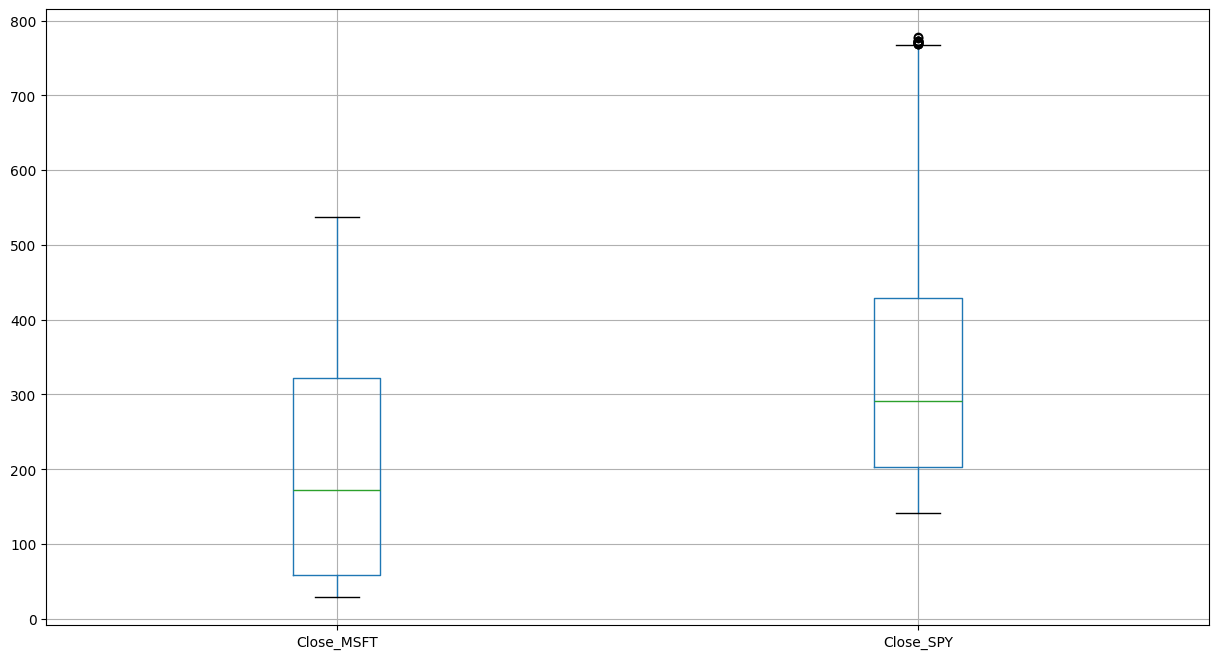

In [ ]:
plt.figure(figsize=(15,8))
stock_df_multiple.boxplot()

In [ ]:
# 2. Check for missing values
stock_df_multiple.isnull().sum()

,0
Close_MSFT,0
Close_SPY,0


In [ ]:
# 3. Find the indexes that are missing
pd.date_range(start = '2014-01-01', end = stock_end_date).difference(stock_df_multiple.index)

DatetimeIndex(['2014-01-01', '2014-01-04', '2014-01-05', '2014-01-11',
               '2014-01-12', '2014-01-18', '2014-01-19', '2014-01-20',
               '2014-01-25', '2014-01-26',
               ...
               '2026-08-02', '2026-08-08', '2026-08-09', '2026-08-15',
               '2026-08-16', '2026-08-22', '2026-08-23', '2026-08-29',
               '2026-08-30', '2026-09-02'],
              dtype='datetime64[ns]', length=1443, freq=None)

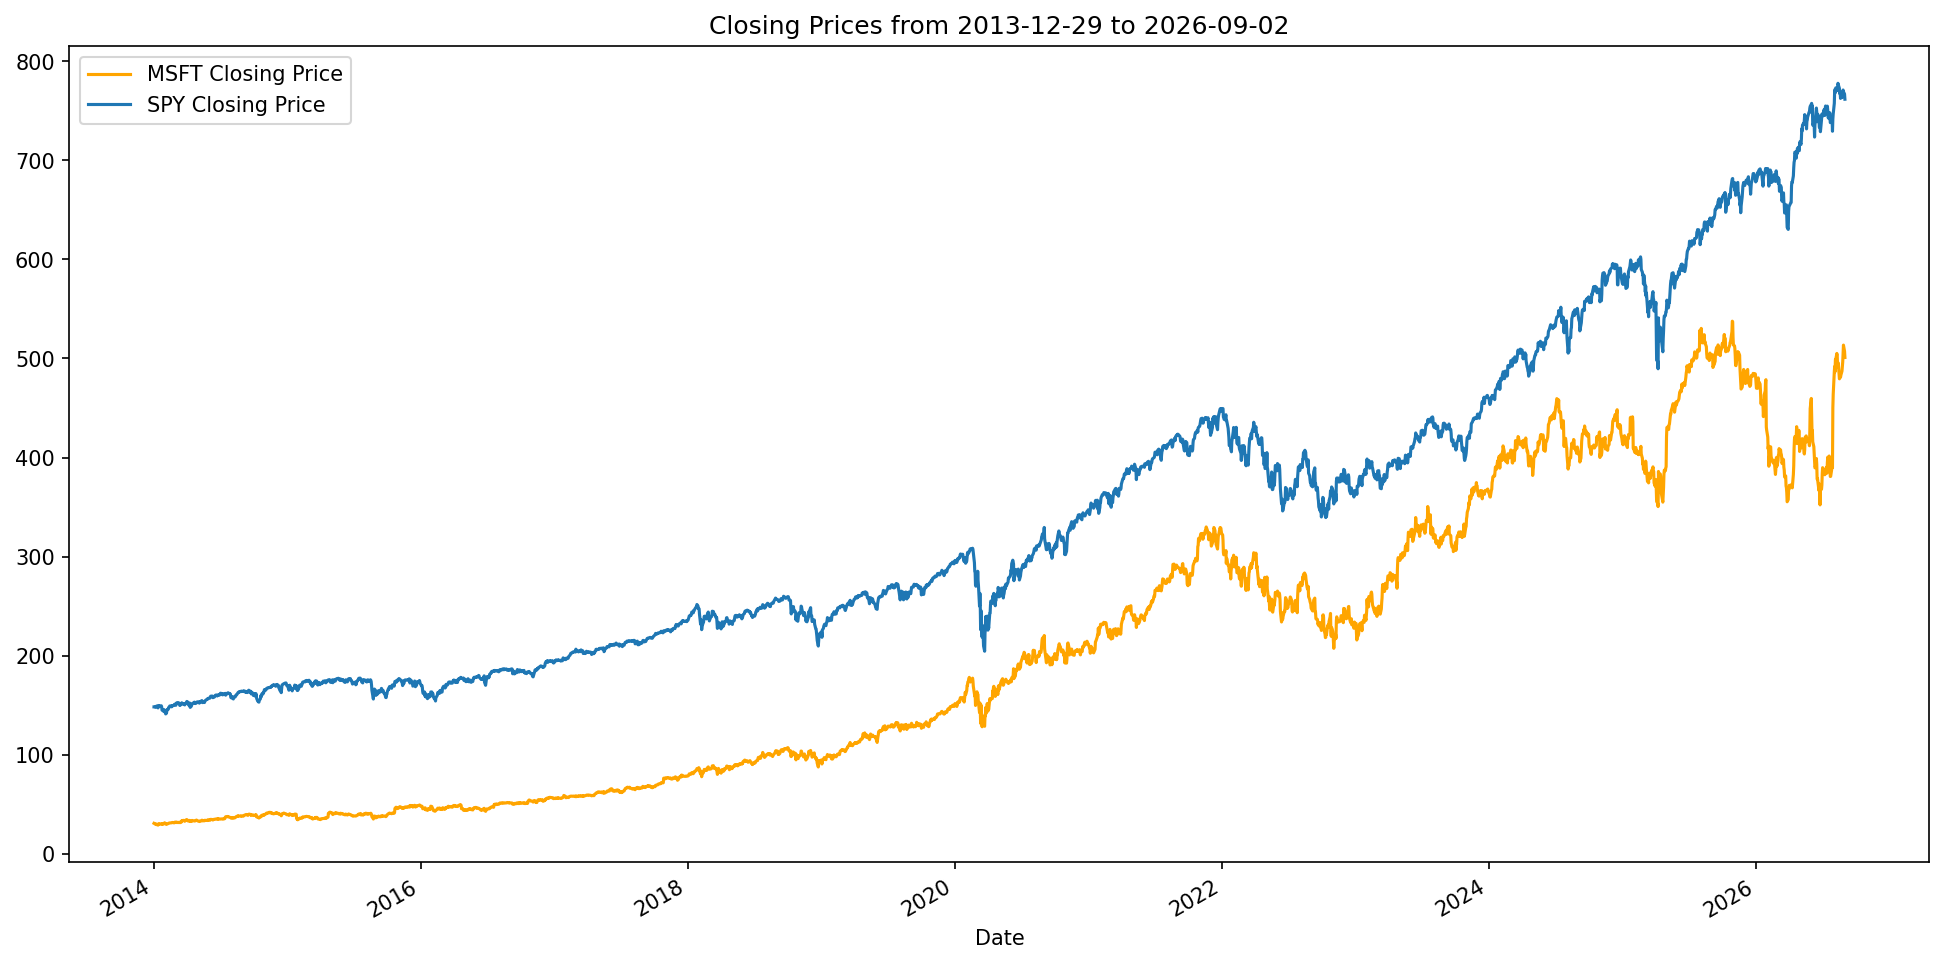

In [ ]:
# Visualizing The Close Price of the stocks

# to set the plot size
plt.figure(figsize=(16, 8), dpi=150) #dpi = resolution. default 100.

# using plot method to plot close prices.
# in plot method we set the label and color of the curve.
stock_df_multiple['Close_MSFT'].plot(label='MSFT Closing Price', color='orange')
stock_df_multiple['Close_SPY'].plot(label='SPY Closing Price')

# adding title to the plot
plt.title('Closing Prices from {} to {}'.format(stock_start_date, stock_end_date))

# adding Label to the x-axis
plt.xlabel('Date')

# adding legend to the curve
plt.legend()


In [ ]:
# 4. Let's complete the broken time series indexes and interpolate (impute missing values) the data

# SEE SLIDES

**Impute Missing Values**

Some time series models work with complete data, and therefore they require the missing data to be replaced with meaningful values before actual analysis. At a high level, missing values in time series are handled in two ways, either dropping them or replacing them. However, dropping missing values can be an inappropriate solution due to the time order of the data and the correlation between observations in adjacent periods.

Estimating a reasonable value such that the components of the series are not distorted is an excellent approach to dealing with missing values in time series. Imputation replaces missing values with values estimated from the same data or observed from the environment with the same conditions underlying the missing data.

Different ways to impute the missing values are as follows.
1. Mean or Median imputation
2. Last Observation Carried Forward (LOCF) or forward fill - the missing value is imputed using the values before it in the time series
3. Next Observation Carried Backward (NOCB) or back fill- the missing values are imputed using an immediate value ahead of them
4. Linear interpolation - estimates unknown values by assuming linear relation within a range of data points
5. Spline interpolation - estimates values that minimize overall curvature, thus obtaining a smooth surface passing through the input points


In [ ]:
stock_df_multiple

,Close_MSFT,Close_SPY
Date,,
2014-01-02,30.636778,148.198456
2014-01-03,30.430649,148.174210
2014-01-06,29.787580,147.744797
2014-01-07,30.018425,148.652145
2014-01-08,29.482529,148.684570
...,...,...
2026-08-26,496.369995,766.080017
2026-08-27,505.059998,771.099976
2026-08-28,513.530029,769.349976


In [ ]:
# first, fill the misssing values with 'NaN'. Reindexing.
stock_df_multiple_NaN = stock_df_multiple.reindex(pd.date_range('2014-01-01', stock_end_date), fill_value= np.nan)
stock_df_multiple_NaN

,Close_MSFT,Close_SPY
2014-01-01,NaN,NaN
2014-01-02,30.636778,148.198456
2014-01-03,30.430649,148.174210
2014-01-04,NaN,NaN
2014-01-05,NaN,NaN
...,...,...
2026-08-29,NaN,NaN
2026-08-30,NaN,NaN
2026-08-31,507.290009,767.049988
2026-09-01,501.019989,761.780029


In [ ]:
# next, let's use ALL the different imputation techniques on MSFT and just the spline on SPY

stock_df_multiple_imputed = stock_df_multiple_NaN.copy()
stock_df_multiple_imputed['MSFT_Spline']= stock_df_multiple_imputed['Close_MSFT'].interpolate(method='spline', order=1, limit=10, limit_direction='both')
stock_df_multiple_imputed['MSFT_Linear']= stock_df_multiple_imputed['Close_MSFT'].interpolate(method='linear', order=1, limit=10, limit_direction='both')
stock_df_multiple_imputed['MSFT_ffill']= stock_df_multiple_imputed['Close_MSFT'].fillna(method ='ffill')
stock_df_multiple_imputed['MSFT_bfill']= stock_df_multiple_imputed['Close_MSFT'].fillna(method ='bfill')
stock_df_multiple_imputed['MSFT_Mean']= stock_df_multiple_imputed['Close_MSFT'].fillna(stock_df_multiple_imputed['Close_MSFT'].mean())
stock_df_multiple_imputed['MSFT_Median']= stock_df_multiple_imputed['Close_MSFT'].fillna(stock_df_multiple_imputed['Close_MSFT'].median())
stock_df_multiple_imputed['SPY_Spline']= stock_df_multiple_imputed['Close_SPY'].interpolate(method='spline', order=1, limit=10, limit_direction='both')

stock_df_multiple_imputed.round(2)


/tmp/ipykernel_3270/694951911.py:6: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  stock_df_multiple_imputed['MSFT_ffill']= stock_df_multiple_imputed['Close_MSFT'].fillna(method ='ffill')
/tmp/ipykernel_3270/694951911.py:7: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  stock_df_multiple_imputed['MSFT_bfill']= stock_df_multiple_imputed['Close_MSFT'].fillna(method ='bfill')


,Close_MSFT,Close_SPY,MSFT_Spline,MSFT_Linear,MSFT_ffill,MSFT_bfill,MSFT_Mean,MSFT_Median,SPY_Spline
2014-01-01,NaN,NaN,29.80,30.64,NaN,30.64,202.70,172.70,148.23
2014-01-02,30.64,148.20,30.64,30.64,30.64,30.64,30.64,30.64,148.20
2014-01-03,30.43,148.17,30.43,30.43,30.43,30.43,30.43,30.43,148.17
2014-01-04,NaN,NaN,29.82,30.22,30.43,29.79,202.70,172.70,148.34
2014-01-05,NaN,NaN,29.83,30.00,30.43,29.79,202.70,172.70,148.37
...,...,...,...,...,...,...,...,...,...
2026-08-29,NaN,NaN,511.37,511.45,513.53,507.29,202.70,172.70,767.70
2026-08-30,NaN,NaN,509.32,509.37,513.53,507.29,202.70,172.70,766.32
2026-08-31,507.29,767.05,507.29,507.29,507.29,507.29,507.29,507.29,767.05
2026-09-01,501.02,761.78,501.02,501.02,501.02,501.02,501.02,501.02,761.78


In [ ]:
# which imputation technique doesnt make sense and why?

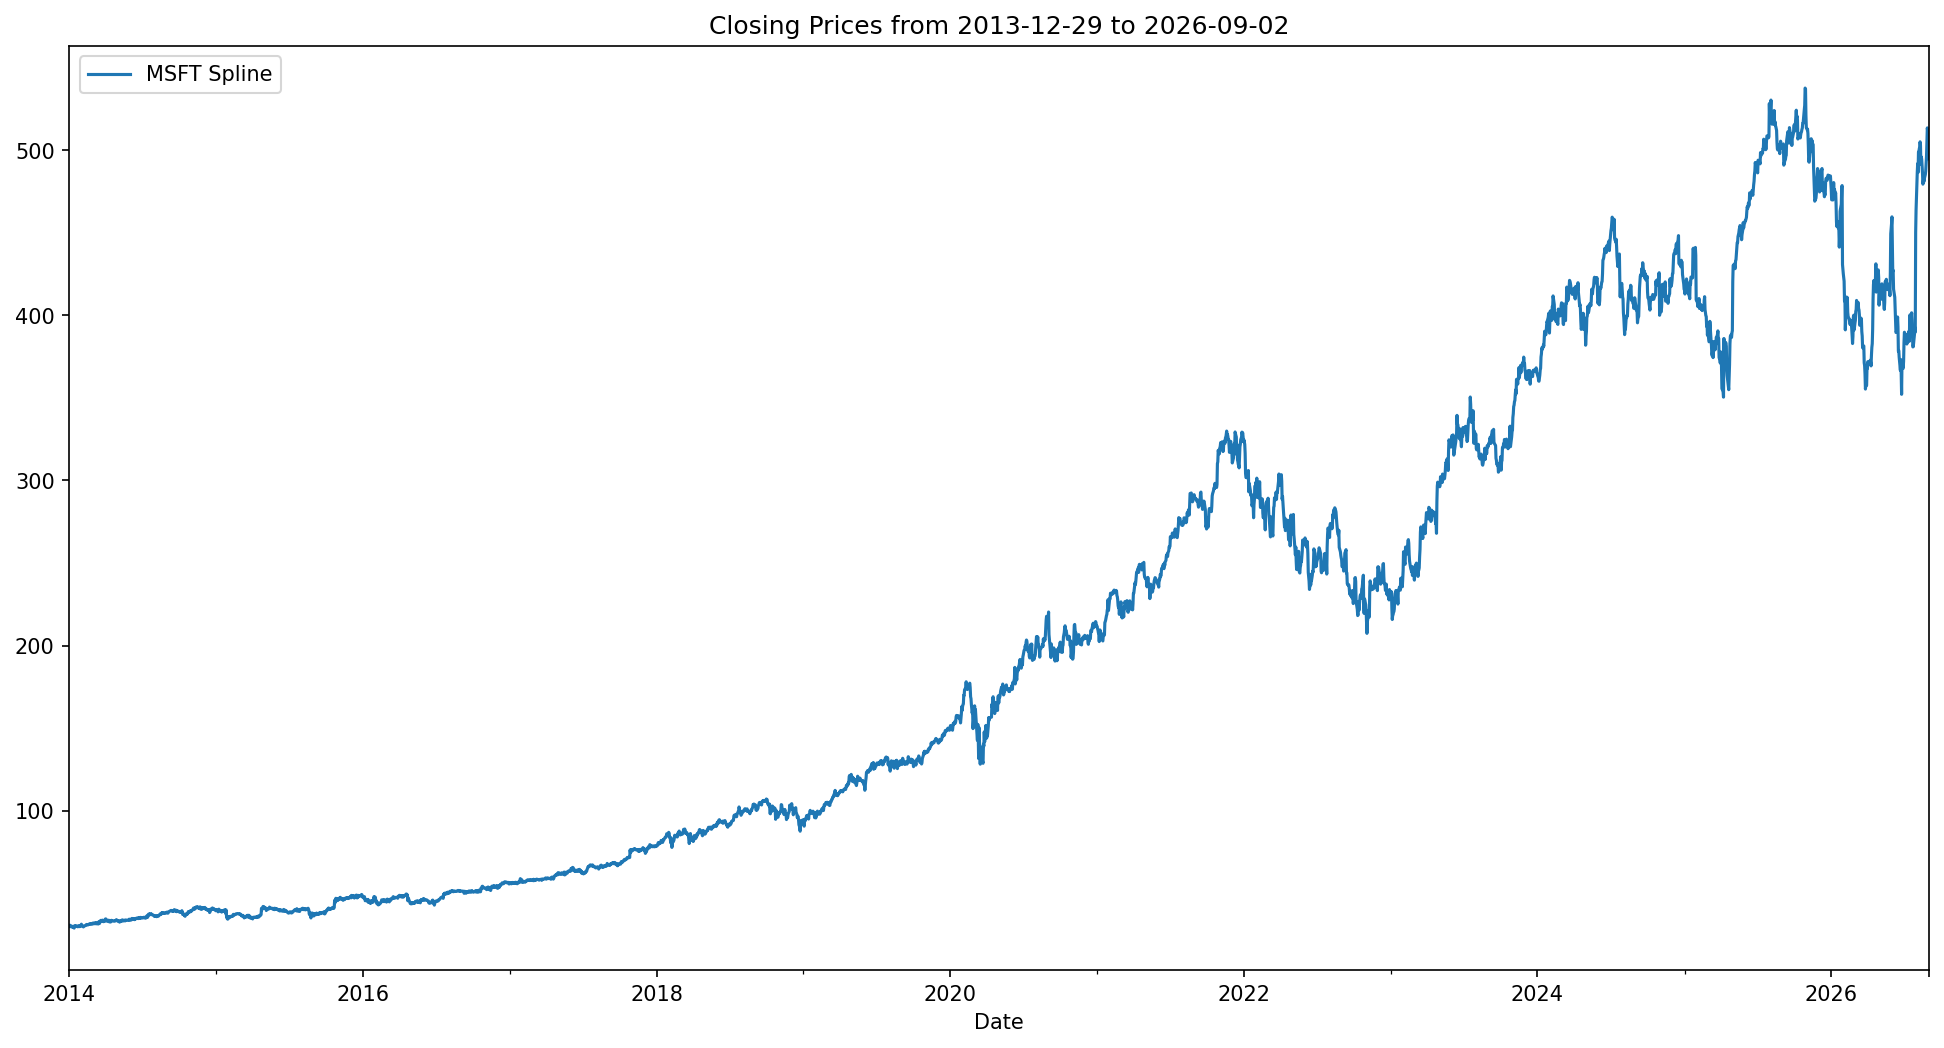

In [ ]:
#Plot

# to set the plot size
plt.figure(figsize=(16, 8), dpi=150)

# using plot method to plot close prices.
# in plot method we set the label and color of the curve.
#stock_df_multiple_imputed['MSFT_Median'].plot(label='MSFT Median', color='orange')
#stock_df_multiple_imputed['MSFT_Linear'].plot(label='MSFT Linear')
#stock_df_multiple_imputed['MSFT_bfill'].plot(label='MSFT Backfill')
stock_df_multiple_imputed['MSFT_Spline'].plot(label='MSFT Spline')


# adding title to the plot
plt.title('Closing Prices from {} to {}'.format(stock_start_date, stock_end_date))

# adding Label to the x-axis
plt.xlabel('Date')

# adding legend to the curve
plt.legend()


In [ ]:
# 5. Time Series Visualizations - Box and Whisker Plots - Outlier Detection
# Source: https://towardsdatascience.com/plotting-time-series-boxplots-5a21f2b76cfe

# ask students - why is outlier detection important?

Brief overview of Outlier Detection techniques can be found here: https://cnvrg.io/anomaly-detection-python/

1. Distribution-based techniques – Minimum Covariance Determinant, Elliptic Envelope
2. Depth-based technique – Isolation Forest
3. Clustering-based technique – Local Outlier Factor
4. Density-based technique – DBSCAN
5. Unified library for Outlier Detection – PyOD
6. Statistical techniques – Interquartile range
7. Visualization techniques – Box-plot

<Axes: xlabel='None', ylabel='SPY_Spline'>

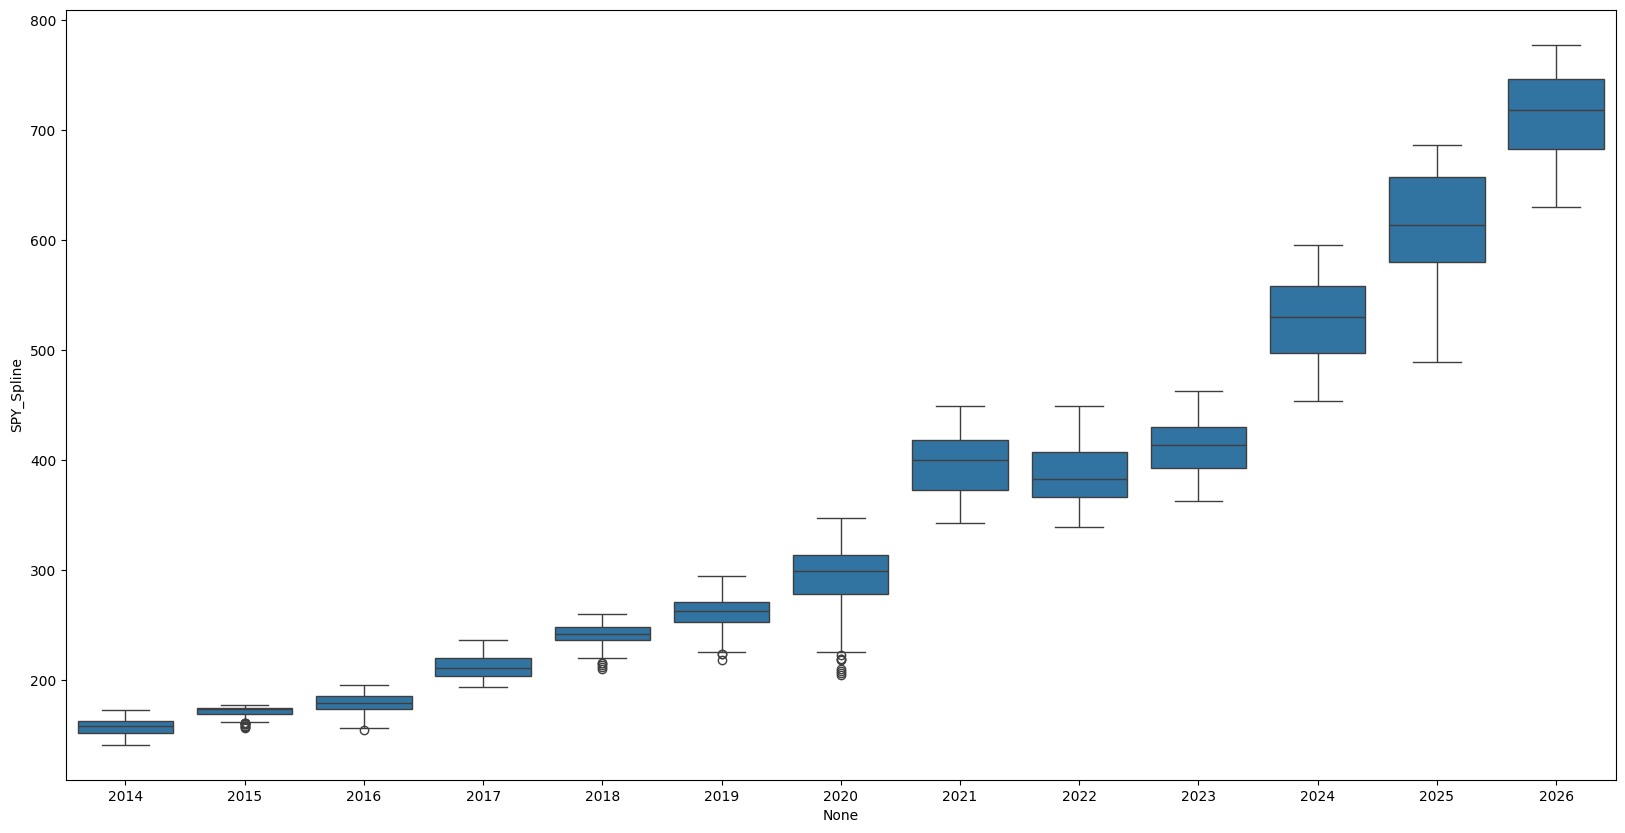

In [ ]:
# price variation for each year

fig, ax = plt.subplots(figsize=(20,10))
sns.boxplot(x = stock_df_multiple_imputed.index.year,
                y = stock_df_multiple_imputed['SPY_Spline'],
                ax = ax)

**Log Scale Plot:** This will show you if the "volatility" (the height of the boxes) is actually increasing, or if it just looks like it's increasing because the stock price is higher. If the boxes stay roughly the same height on a log scale, the stock's relative risk hasn't changed.

/tmp/ipykernel_3270/3428066186.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=stock_df_multiple_imputed.index.year,


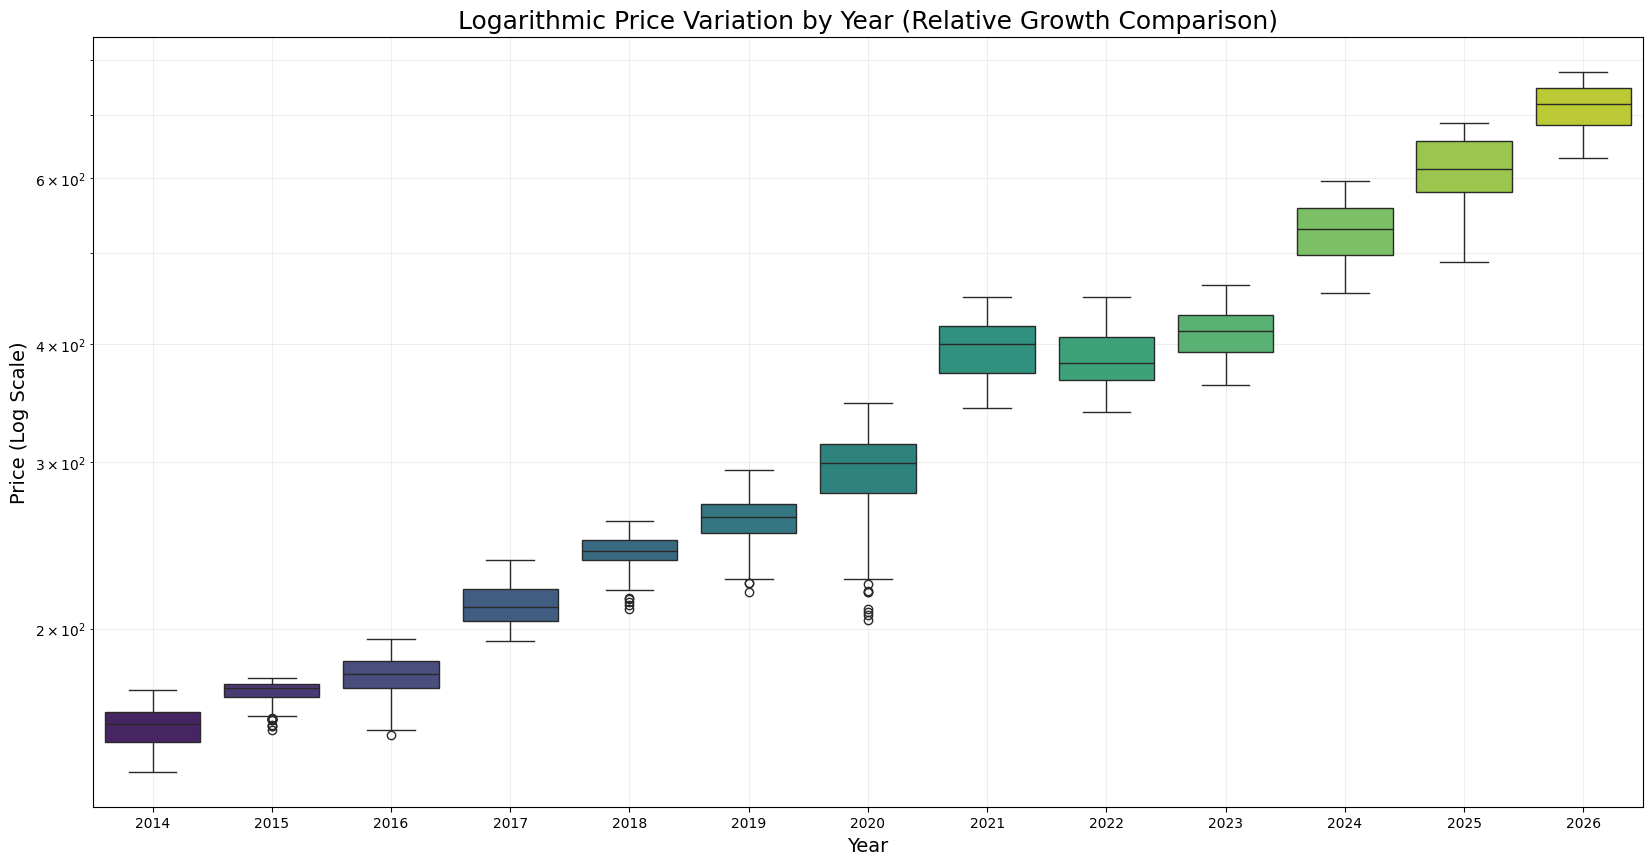

In [ ]:
# Create the plot
fig, ax = plt.subplots(figsize=(20, 10))

# We use the same boxplot logic but add a log scale to the Y-axis
sns.boxplot(x=stock_df_multiple_imputed.index.year,
            y=stock_df_multiple_imputed['SPY_Spline'],
            palette="viridis", # Adds a nice color gradient over the years
            ax=ax)

# SET TO LOG SCALE
ax.set_yscale('log')

# Update labels to reflect the change
ax.set_title('Logarithmic Price Variation by Year (Relative Growth Comparison)', fontsize=18)
ax.set_ylabel('Price (Log Scale)', fontsize=14)
ax.set_xlabel('Year', fontsize=14)
ax.grid(True, which="both", ls="-", alpha=0.2) # Adding gridlines helps read log scales

plt.show()

**The Insight:**

In a standard linear plot, as a stock price goes from $\$50$ to $\$500$, the "boxes" (volatility) usually get taller and taller because a $2\%$ move on $\$500$ is much larger in dollars than a $2\%$ move on $\$50$.

1. If the Log Plot looks similar to the Original: It means your percentage volatility is constant.

2. The Verdict: Even though the stock price is much higher now than it was in 2014, the relative risk (the percentage swings) has remained stable. The asset isn't getting "crazier" or "riskier" just because it's more expensive; it's growing at a consistent exponential rate.

3. Key Takeaway: If the log boxes were getting taller over time, that would be a warning sign that the stock is becoming more unstable/volatile relative to its price.




**Year-over-Year (YoY) Growth %:**

Instead of plotting the raw price, plot the percentage change from the first day of each year. This levels the playing field so you can see which year was actually the strongest performer relative to its start.

/tmp/ipykernel_3270/2522309820.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Year', y='Growth_Pct', data=df_yoy, palette="magma")


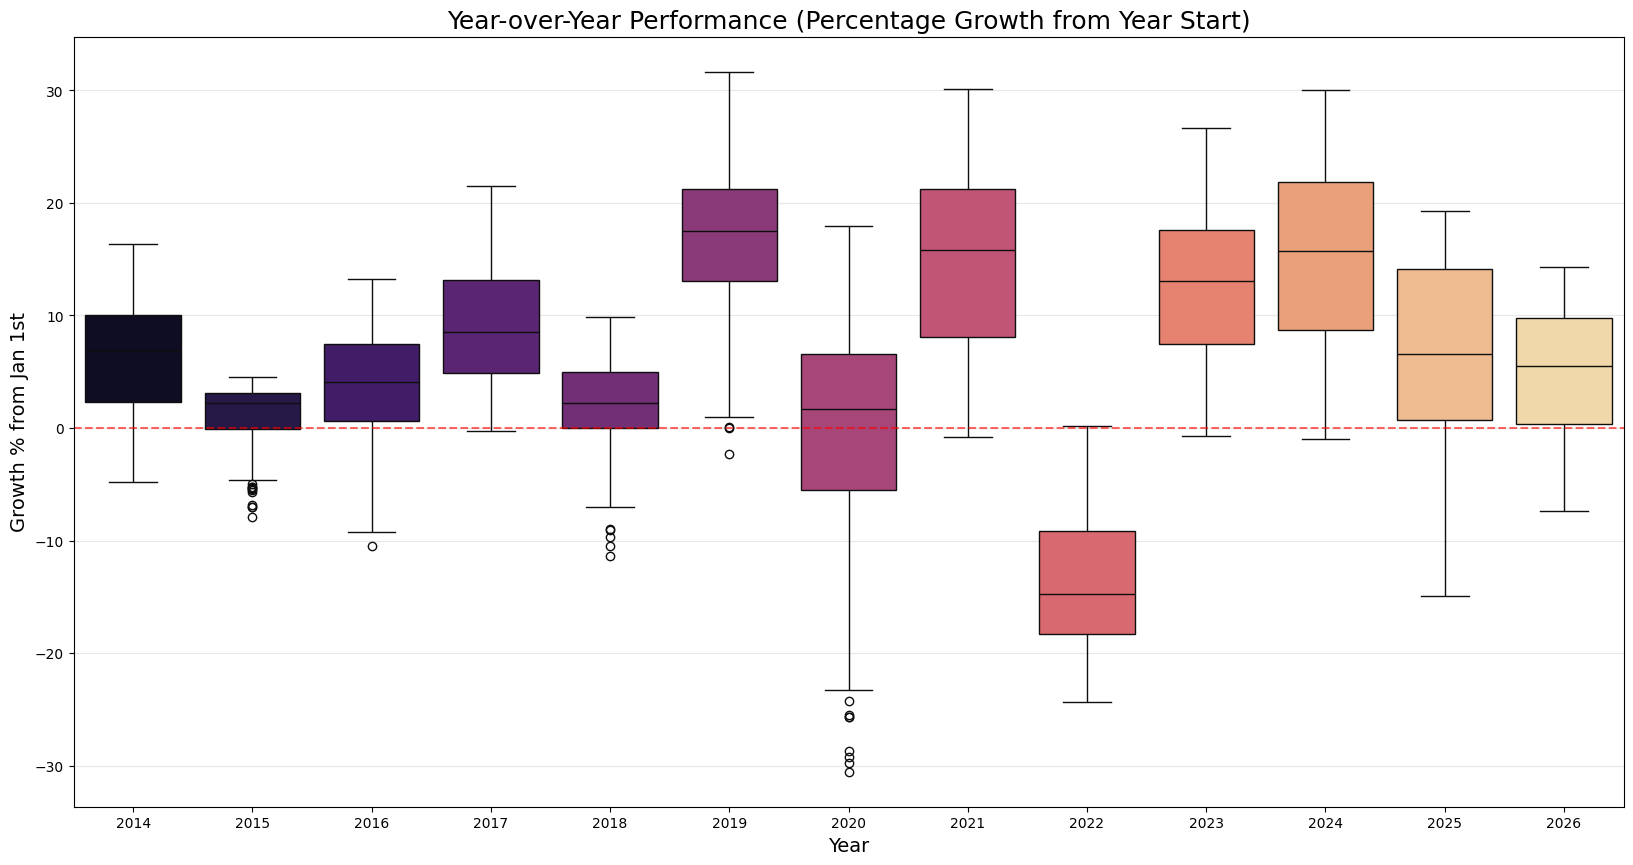

In [ ]:
# 1. Calculate the YoY Growth %
# We group by year and divide every price by the first price recorded in that specific year
yoy_growth = stock_df_multiple_imputed.groupby(stock_df_multiple_imputed.index.year)['SPY_Spline'].transform(
    lambda x: (x / x.iloc[0] - 1) * 100
)

# 2. Create a temporary DataFrame for plotting
df_yoy = pd.DataFrame({
    'Year': stock_df_multiple_imputed.index.year,
    'Growth_Pct': yoy_growth
})

# 3. Plot
plt.figure(figsize=(20, 10))
sns.boxplot(x='Year', y='Growth_Pct', data=df_yoy, palette="magma")

# Add a horizontal line at 0 to see which months/years were in the red
plt.axhline(0, color='red', linestyle='--', alpha=0.6)

plt.title('Year-over-Year Performance (Percentage Growth from Year Start)', fontsize=18)
plt.ylabel('Growth % from Jan 1st', fontsize=14)
plt.xlabel('Year', fontsize=14)
plt.grid(axis='y', alpha=0.3)

plt.show()

**Insights: YoY Performance**

1. 2022 (Bear): The only year where the entire distribution sits below the 0% baseline, indicating a sustained downward trend with sharp "drawdown" outliers.

2. 2023 (Recovery): A transitional "climb-back" phase where the stock stabilized and rebounded to a positive median growth of 15%–20%.

3. 2024 (Bull): The strongest regime; even the yearly "lows" remain above the January 1st price, signaling high-conviction buying and aggressive momentum.

<Axes: xlabel='None', ylabel='SPY_Spline'>

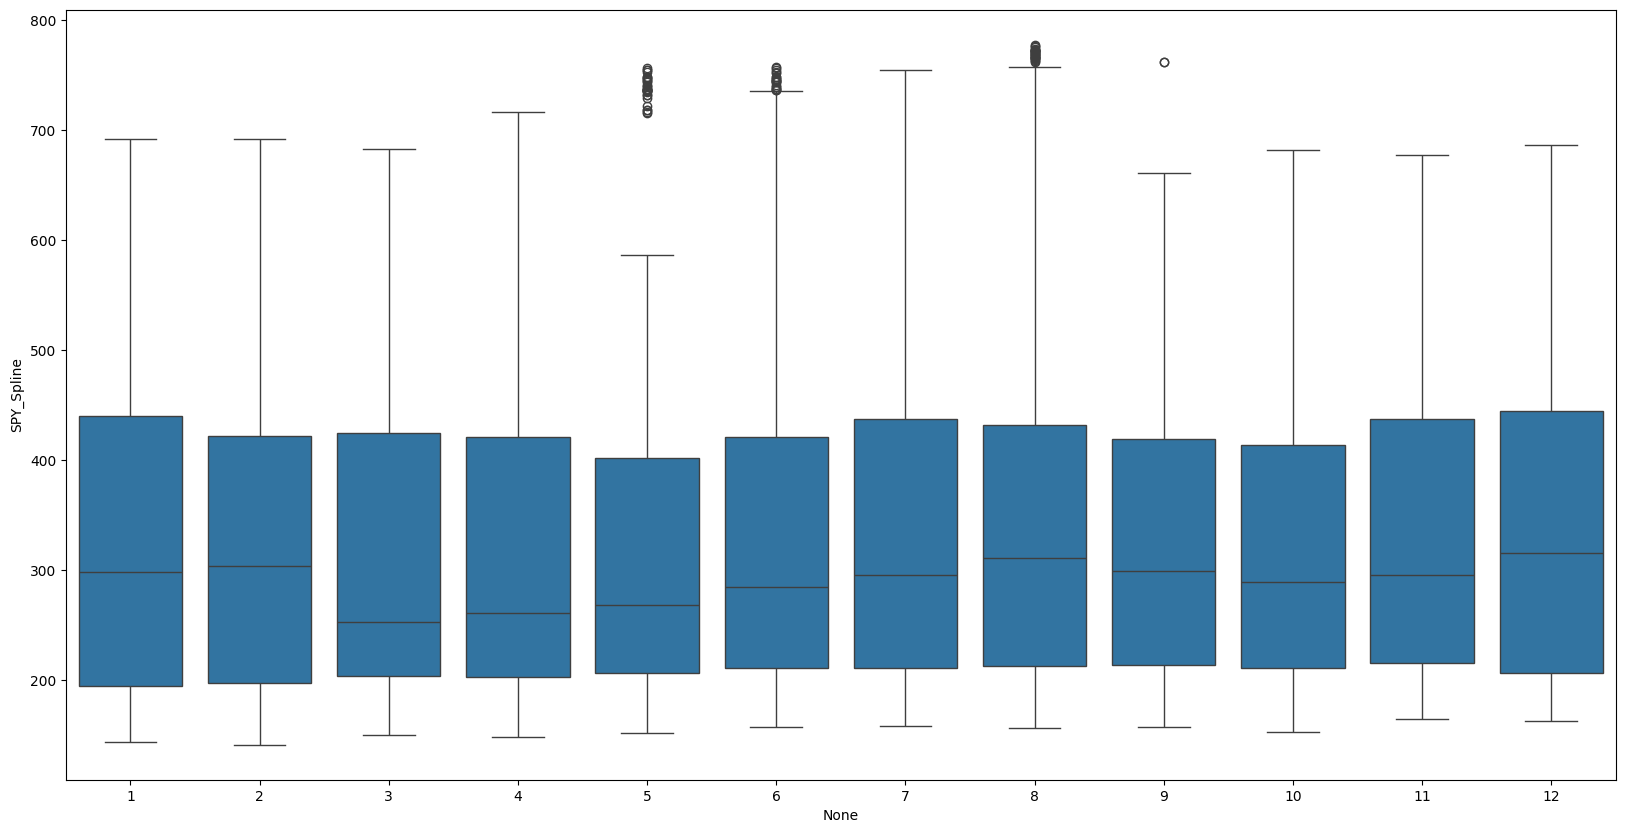

In [ ]:
# price variation for each month

fig, ax = plt.subplots(figsize=(20,10))
sns.boxplot(x = stock_df_multiple_imputed.index.month,
                y = stock_df_multiple_imputed['SPY_Spline'],
                ax = ax)

**Monthly Analysis**

1. When plotted as absolute prices, the monthly distributions appear uniform with high variance. This is a result of long-term price appreciation (trend) masking seasonal effects.

2. **Key Insight:** To isolate true seasonality (e.g., "Is March usually better than August?"), we must analyze percentage returns rather than price levels.


/tmp/ipykernel_3270/2201054518.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x = stock_df_multiple_imputed.index.month,


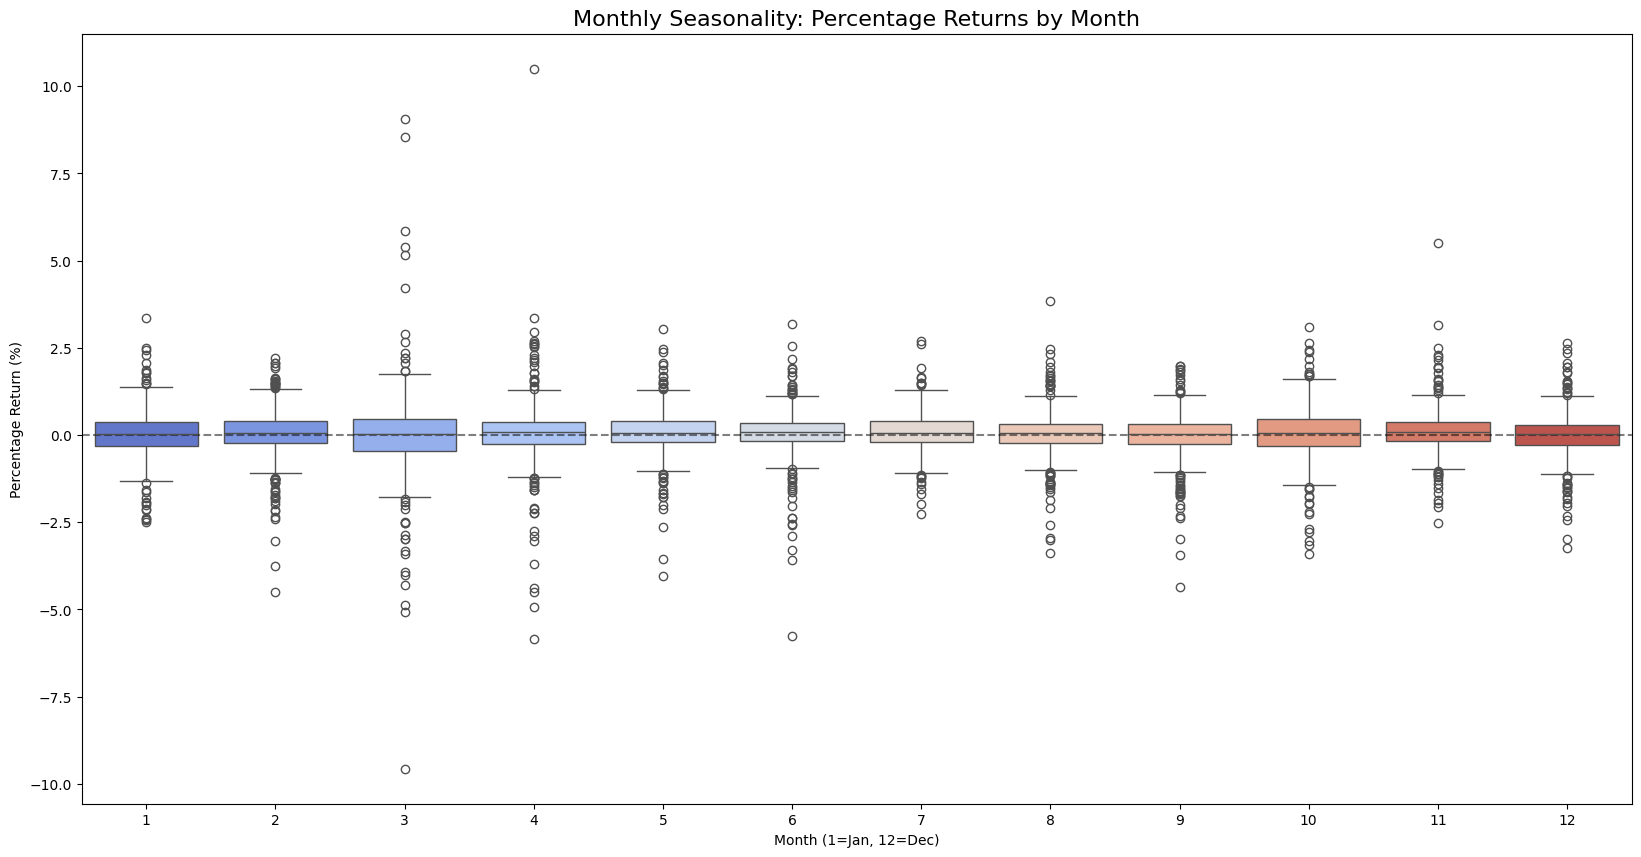

In [ ]:
# 1. Calculate Monthly Return %
stock_df_multiple_imputed['Monthly_Return'] = stock_df_multiple_imputed['SPY_Spline'].pct_change() * 100

# 2. Plotting Returns instead of Price
fig, ax = plt.subplots(figsize=(20,10))
sns.boxplot(x = stock_df_multiple_imputed.index.month,
            y = stock_df_multiple_imputed['Monthly_Return'],
            palette="coolwarm", # Red for potentially volatile, blue for cool
            ax = ax)

plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.title('Monthly Seasonality: Percentage Returns by Month', fontsize=16)
plt.xlabel('Month (1=Jan, 12=Dec)')
plt.ylabel('Percentage Return (%)')
plt.show()

In [ ]:
# 6. Resampling

Resampling involves changing the frequency of your time series observations. Two types of
resampling are:
1. Upsampling: Where you increase the frequency of the samples, such as from minutes to seconds.
2. Downsampling: Where you decrease the frequency of the samples, such as from days to months.

In both cases, data must be invented. In the case of upsampling, care may be needed in
determining how the fine-grained observations are calculated using interpolation. In the case of
downsampling, care may be needed in selecting the summary statistics used to calculate the
new aggregated values.

There are perhaps two main reasons why you may be interested in resampling your time
series data:
1. Problem Framing: Resampling may be required if your data is not available at the same frequency that you want to make predictions.
2. Feature Engineering: Resampling can also be used to provide additional structure or insight into the learning problem for supervised learning models.

There is a lot of overlap between these two cases. For example, you may have daily data
and want to predict a monthly problem. You could use the daily data directly or you could
downsample it to monthly data and develop your model. A feature engineering perspective may
use observations and summaries of observations from both time scales and more in developing a
model.

In [ ]:
df_resample = stock_df_multiple_imputed.copy()

# extract only the spline variables
df_resample = df_resample[['MSFT_Spline', 'SPY_Spline']].round(2)
df_resample

,MSFT_Spline,SPY_Spline
2014-01-01,29.80,148.23
2014-01-02,30.64,148.20
2014-01-03,30.43,148.17
2014-01-04,29.82,148.34
2014-01-05,29.83,148.37
...,...,...
2026-08-29,511.37,767.70
2026-08-30,509.32,766.32
2026-08-31,507.29,767.05
2026-09-01,501.02,761.78


In [ ]:
# downsample the data from days to months to reduce variability in the data
# observe the stock prices on a monthly basis

df_resample_months = df_resample.groupby(pd.Grouper(freq='MS')).median()
#df_resample_months = df_resample.resample('M').median() #another way of resampling
df_resample_months

,MSFT_Spline,SPY_Spline
2014-01-01,29.900,148.370
2014-02-01,30.860,148.275
2014-03-01,32.590,151.520
2014-04-01,33.185,151.765
2014-05-01,33.470,153.330
...,...,...
2026-05-01,415.250,737.270
2026-06-01,389.810,740.420
2026-07-01,388.550,746.260
2026-08-01,491.710,769.060


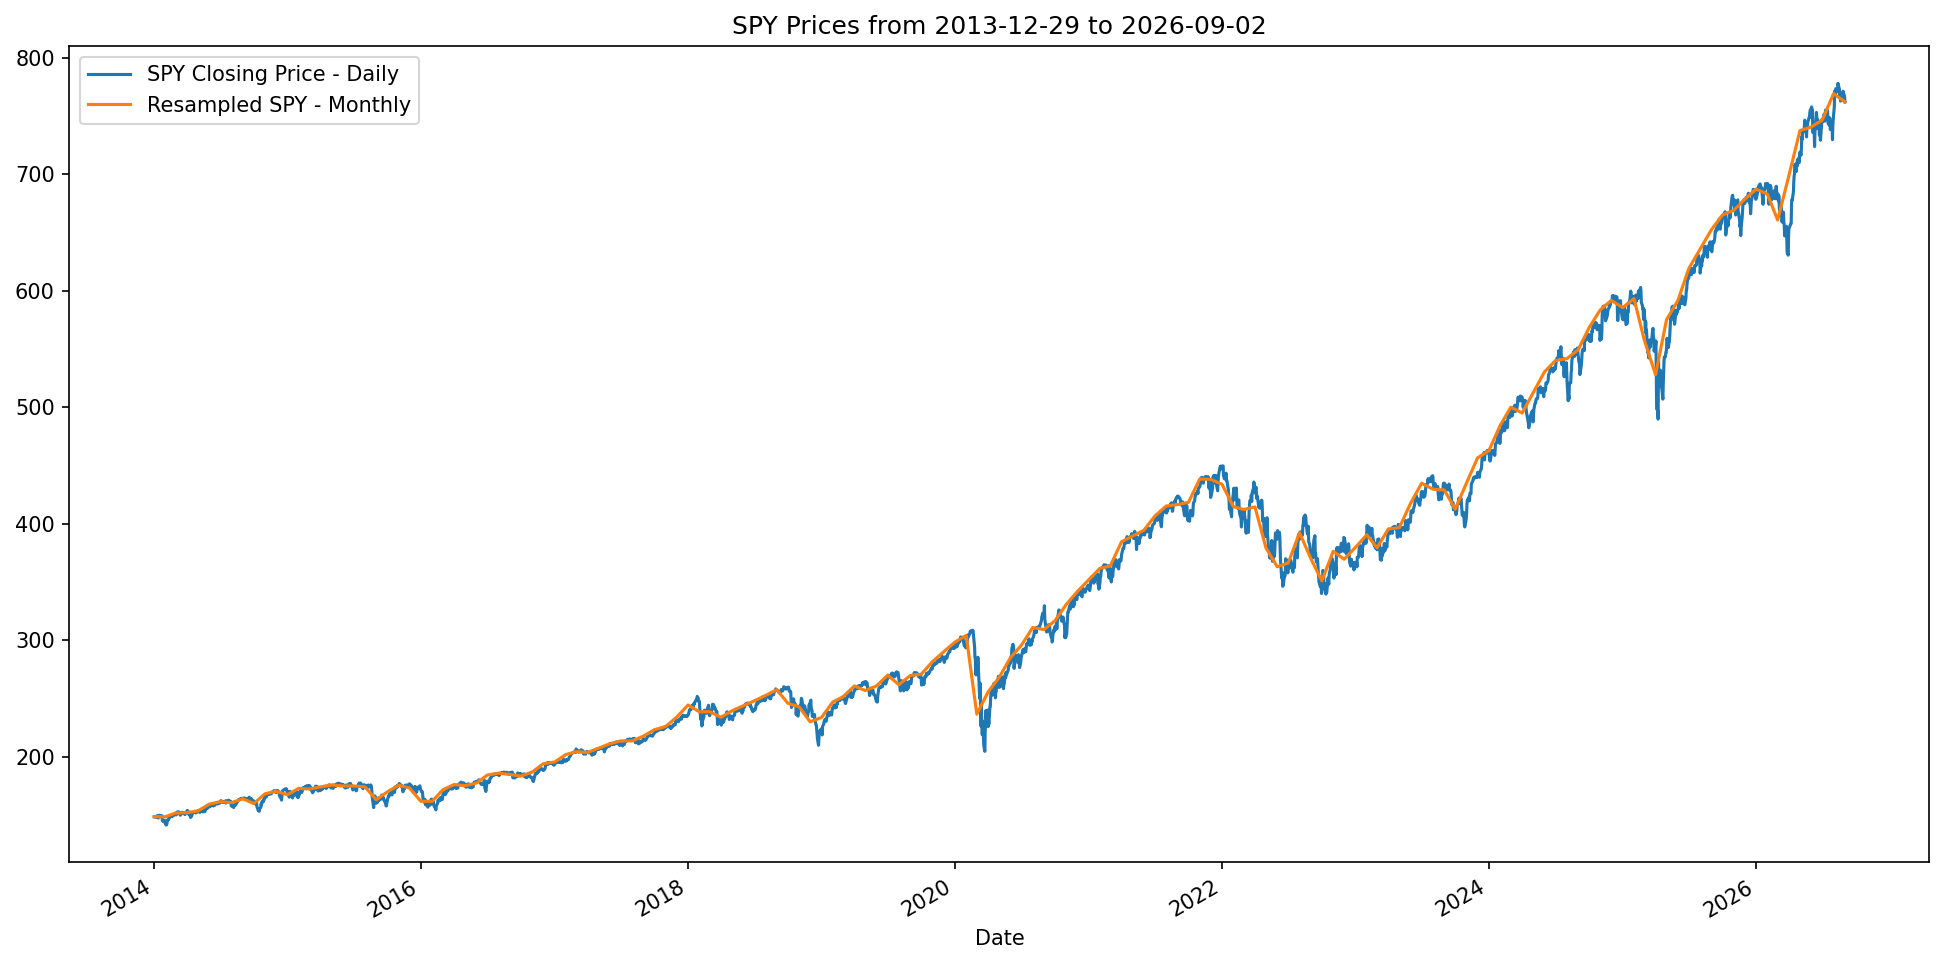

In [ ]:
#Plot monthly data

# to set the plot size
plt.figure(figsize=(16, 8), dpi=150)

# using plot method to plot close prices.
# in plot method we set the label and color of the curve.
#df_resample_months['MSFT_Spline'].plot(label='MSFT')
stock_df_multiple['Close_SPY'].plot(label='SPY Closing Price - Daily')
df_resample_months['SPY_Spline'].plot(label='Resampled SPY - Monthly')


# adding title to the plot
plt.title('SPY Prices from {} to {}'.format(stock_start_date, stock_end_date))

# adding Label to the x-axis
plt.xlabel('Date')

# adding legend to the curve
plt.legend()

In [ ]:
# 6. Autocorrelation or ACF plot


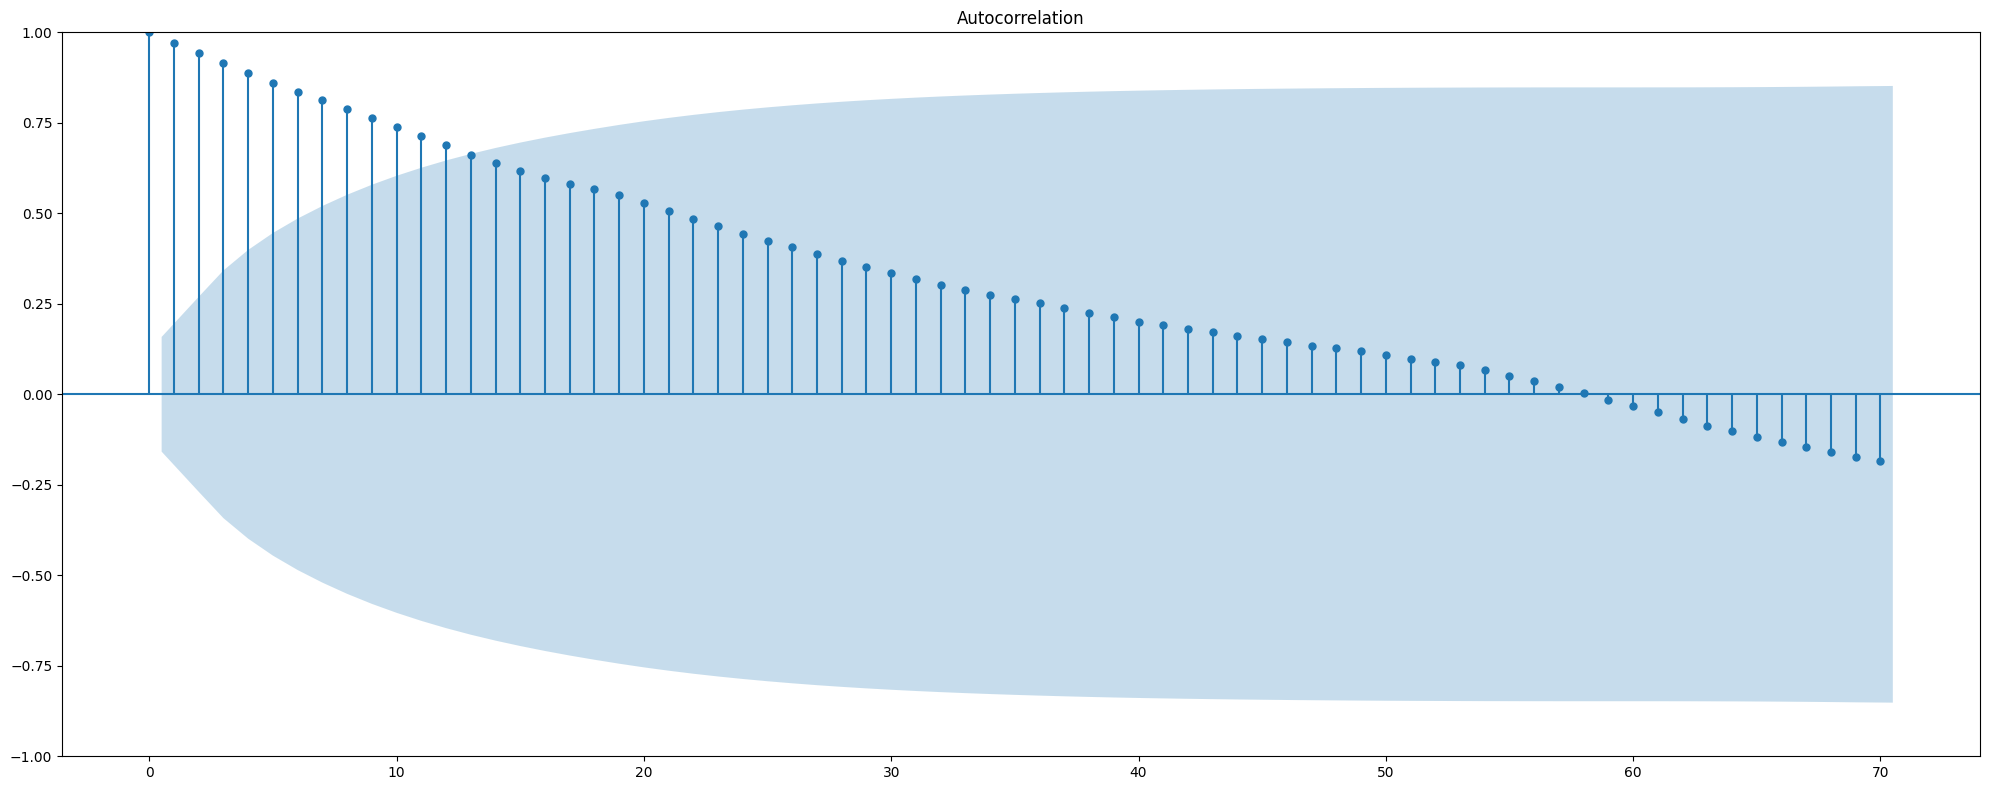

In [ ]:
# Calculate the ACF (via statsmodel)
# Source: https://www.alpharithms.com/autocorrelation-time-series-python-432909/

fig = plot_acf(df_resample_months['SPY_Spline'], lags=70)
fig.set_size_inches((20, 8))
# Tight layout to realign things
fig.tight_layout()
plt.show()

In [ ]:
# 7. Time Series Decomposition
# Source: https://stackoverflow.com/questions/20672236/time-series-decomposition-function-in-python

Time series decomposition is a process of deconstructing a time series into the following components:

1. Trend — general movement over time
2. Seasonal — behaviors captured in individual seasonal periods
3. Residual — everything not captured by trend and seasonal components


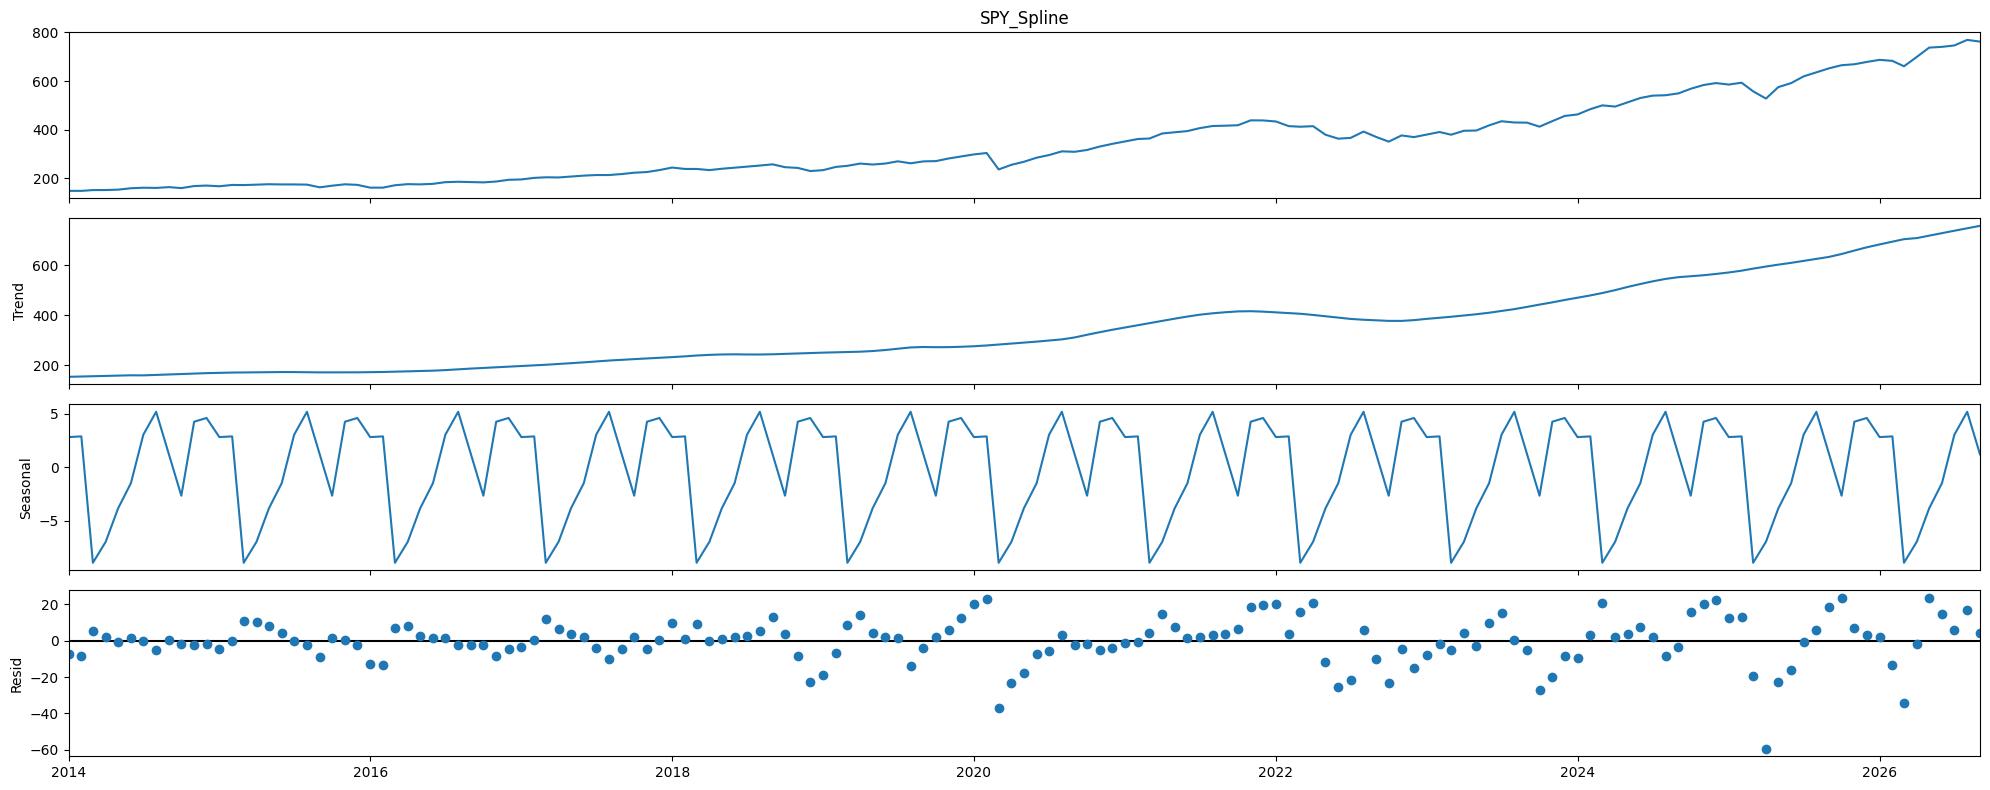

In [ ]:
res = sm.tsa.seasonal_decompose(df_resample_months['SPY_Spline'], period=12, extrapolate_trend='freq')
fig = res.plot()
fig.set_size_inches((20, 8))
# Tight layout to realign things
fig.tight_layout()
plt.show()

In [ ]:
# We can extract the trend, seasonality, and error terms
# going forward let us only concentrate on one time series - SPY

In [ ]:
spy_df = df_resample_months[['SPY_Spline']]

# extract the decomposed terms
spy_df['trend'] = res.trend
spy_df['seasonal'] = res.seasonal
spy_df['error'] = res.resid
spy_df

,SPY_Spline,trend,seasonal,error
2014-01-01,148.370,152.915881,2.807814,-7.353694
2014-02-01,148.275,154.136307,2.872685,-8.733992
2014-03-01,151.520,155.356733,-8.933422,5.096689
2014-04-01,151.765,156.577159,-6.970580,2.158421
2014-05-01,153.330,157.797585,-3.848076,-0.619509
...,...,...,...,...
2026-05-01,737.270,717.656108,-3.848076,23.461968
2026-06-01,740.420,727.449374,-1.494321,14.464947
2026-07-01,746.260,737.242639,3.028832,5.988528
2026-08-01,769.060,747.035905,5.171418,16.852677


In [ ]:
152.915881+2.807814	-7.353694

148.37000100000003

<Axes: >

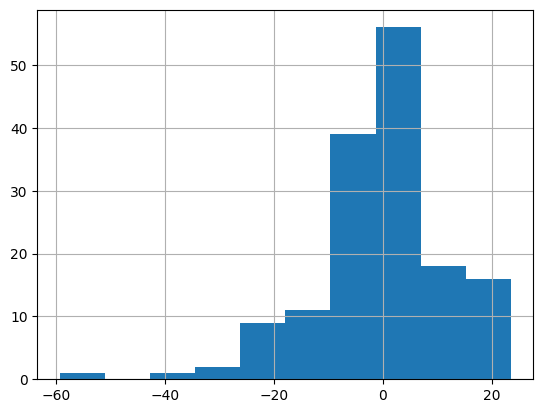

In [ ]:
spy_df['error'].hist()

In [ ]:
# 8 . Time Series Viz - pairplot
# Source: https://seaborn.pydata.org/generated/seaborn.pairplot.html

In [ ]:
df_resample_months

,MSFT_Spline,SPY_Spline
2014-01-01,29.900,148.370
2014-02-01,30.860,148.275
2014-03-01,32.590,151.520
2014-04-01,33.185,151.765
2014-05-01,33.470,153.330
...,...,...
2026-05-01,415.250,737.270
2026-06-01,389.810,740.420
2026-07-01,388.550,746.260
2026-08-01,491.710,769.060


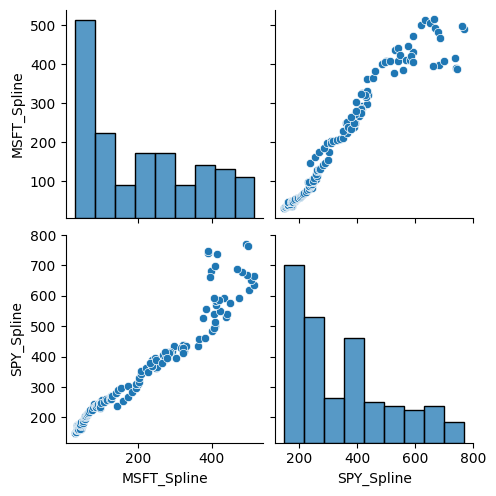

In [ ]:
sns.pairplot(df_resample_months)


In [ ]:
np.corrcoef(df_resample_months['MSFT_Spline'],df_resample_months['SPY_Spline'])

array([[1.      , 0.966917],
       [0.966917, 1.      ]])

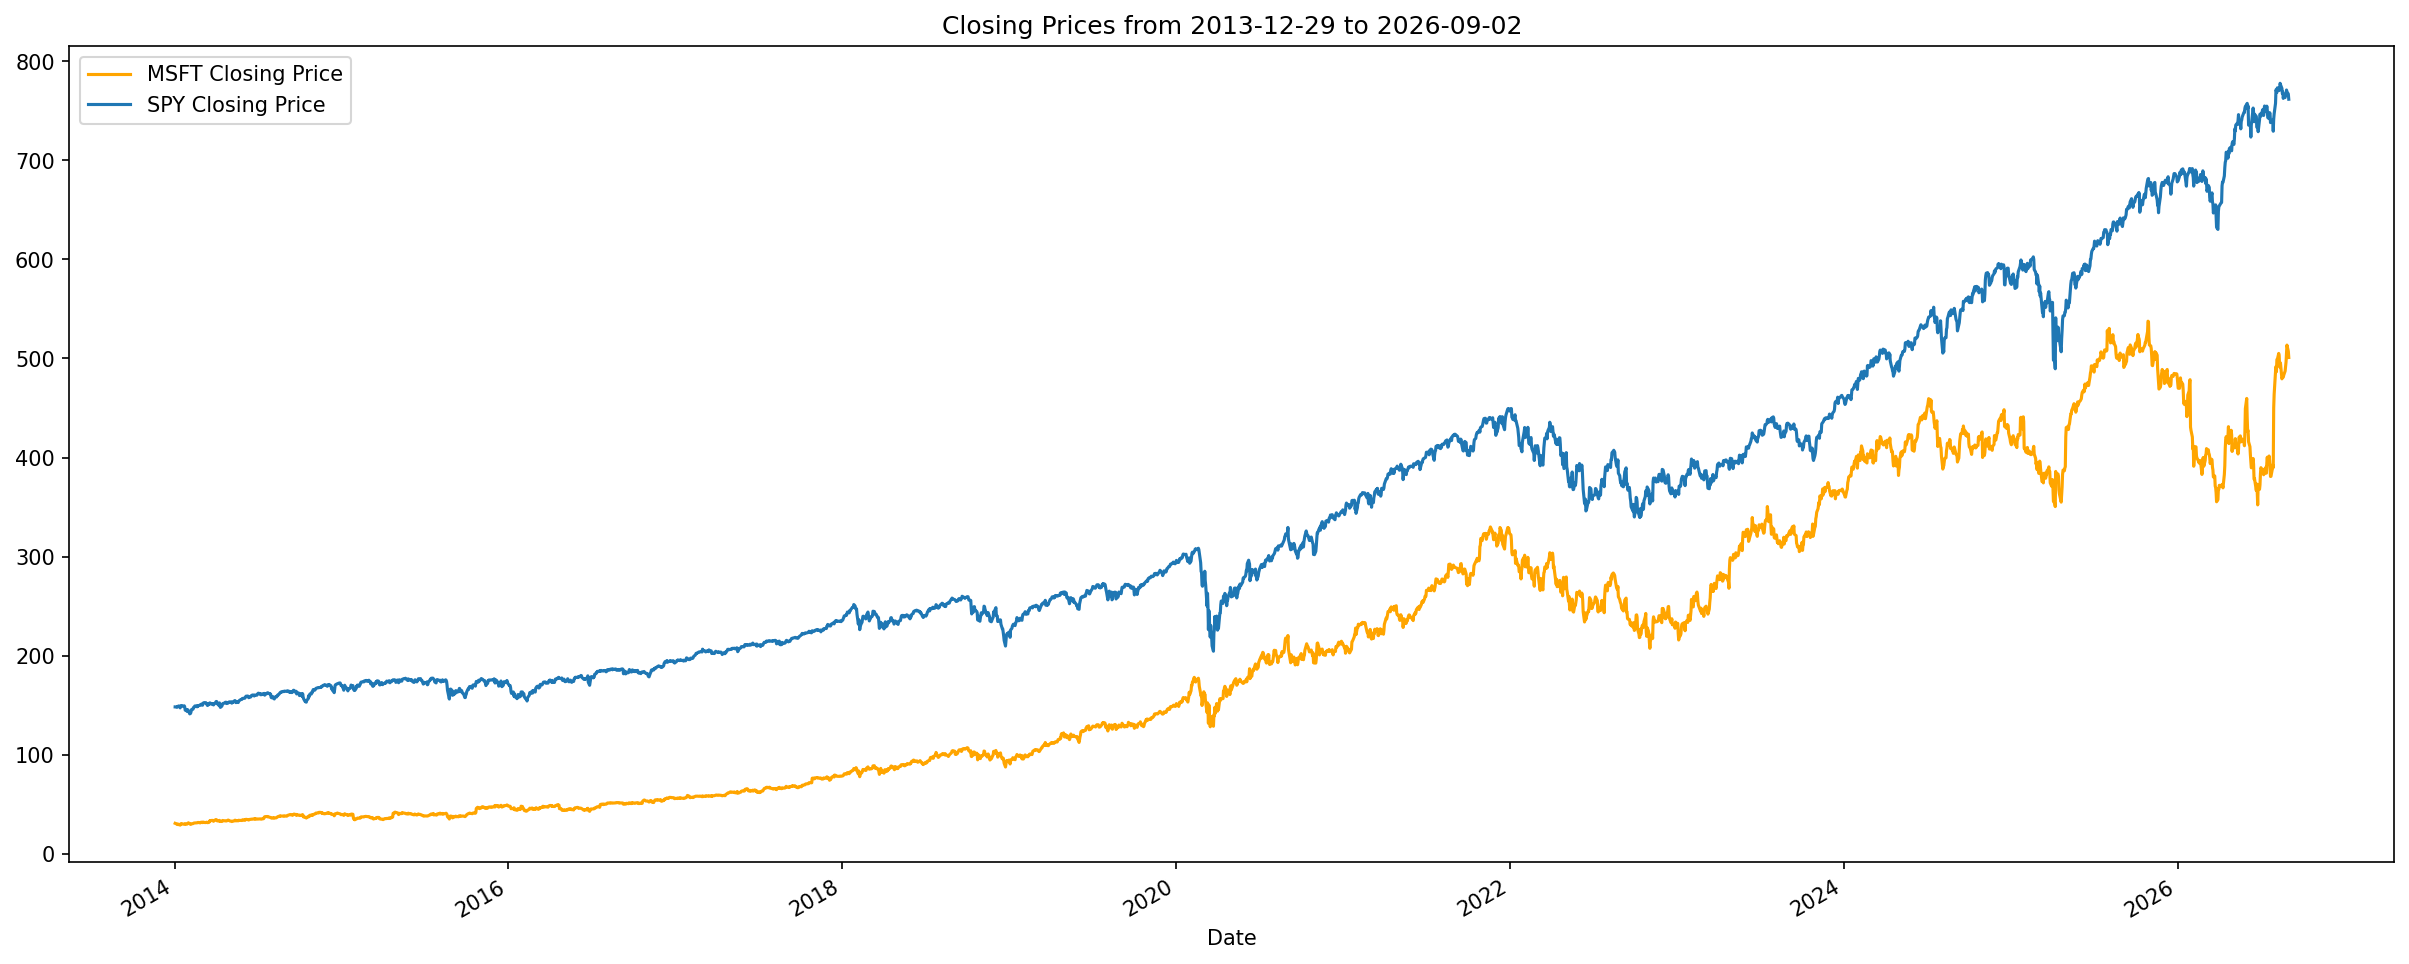

In [ ]:
# Visualizing The Close Price of the stocks

# to set the plot size
plt.figure(figsize=(20, 8), dpi=150) #dpi = resolution. default 100.

# using plot method to plot close prices.
# in plot method we set the label and color of the curve.
stock_df_multiple['Close_MSFT'].plot(label='MSFT Closing Price', color='orange')
stock_df_multiple['Close_SPY'].plot(label='SPY Closing Price')

# adding title to the plot
plt.title('Closing Prices from {} to {}'.format(stock_start_date, stock_end_date))

# adding Label to the x-axis
plt.xlabel('Date')

# adding legend to the curve
plt.legend()


In [ ]:
df_resample_months

,MSFT_Spline,SPY_Spline
2014-01-01,29.900,148.370
2014-02-01,30.860,148.275
2014-03-01,32.590,151.520
2014-04-01,33.185,151.765
2014-05-01,33.470,153.330
...,...,...
2026-05-01,415.250,737.270
2026-06-01,389.810,740.420
2026-07-01,388.550,746.260
2026-08-01,491.710,769.060


In [ ]:
# spurious correlation - https://www.statology.org/spurious-correlation-examples/

In [ ]:
#lets understand spurious correlation using two white noise series.
#The two series should not be correlated with each other

In [ ]:
# generate two white noise series with 1000 samples each
# set random seed for reproducibility
np.random.seed(42)

wn1 = np.random.normal(size=1000)
wn2 = np.random.normal(size=1000)

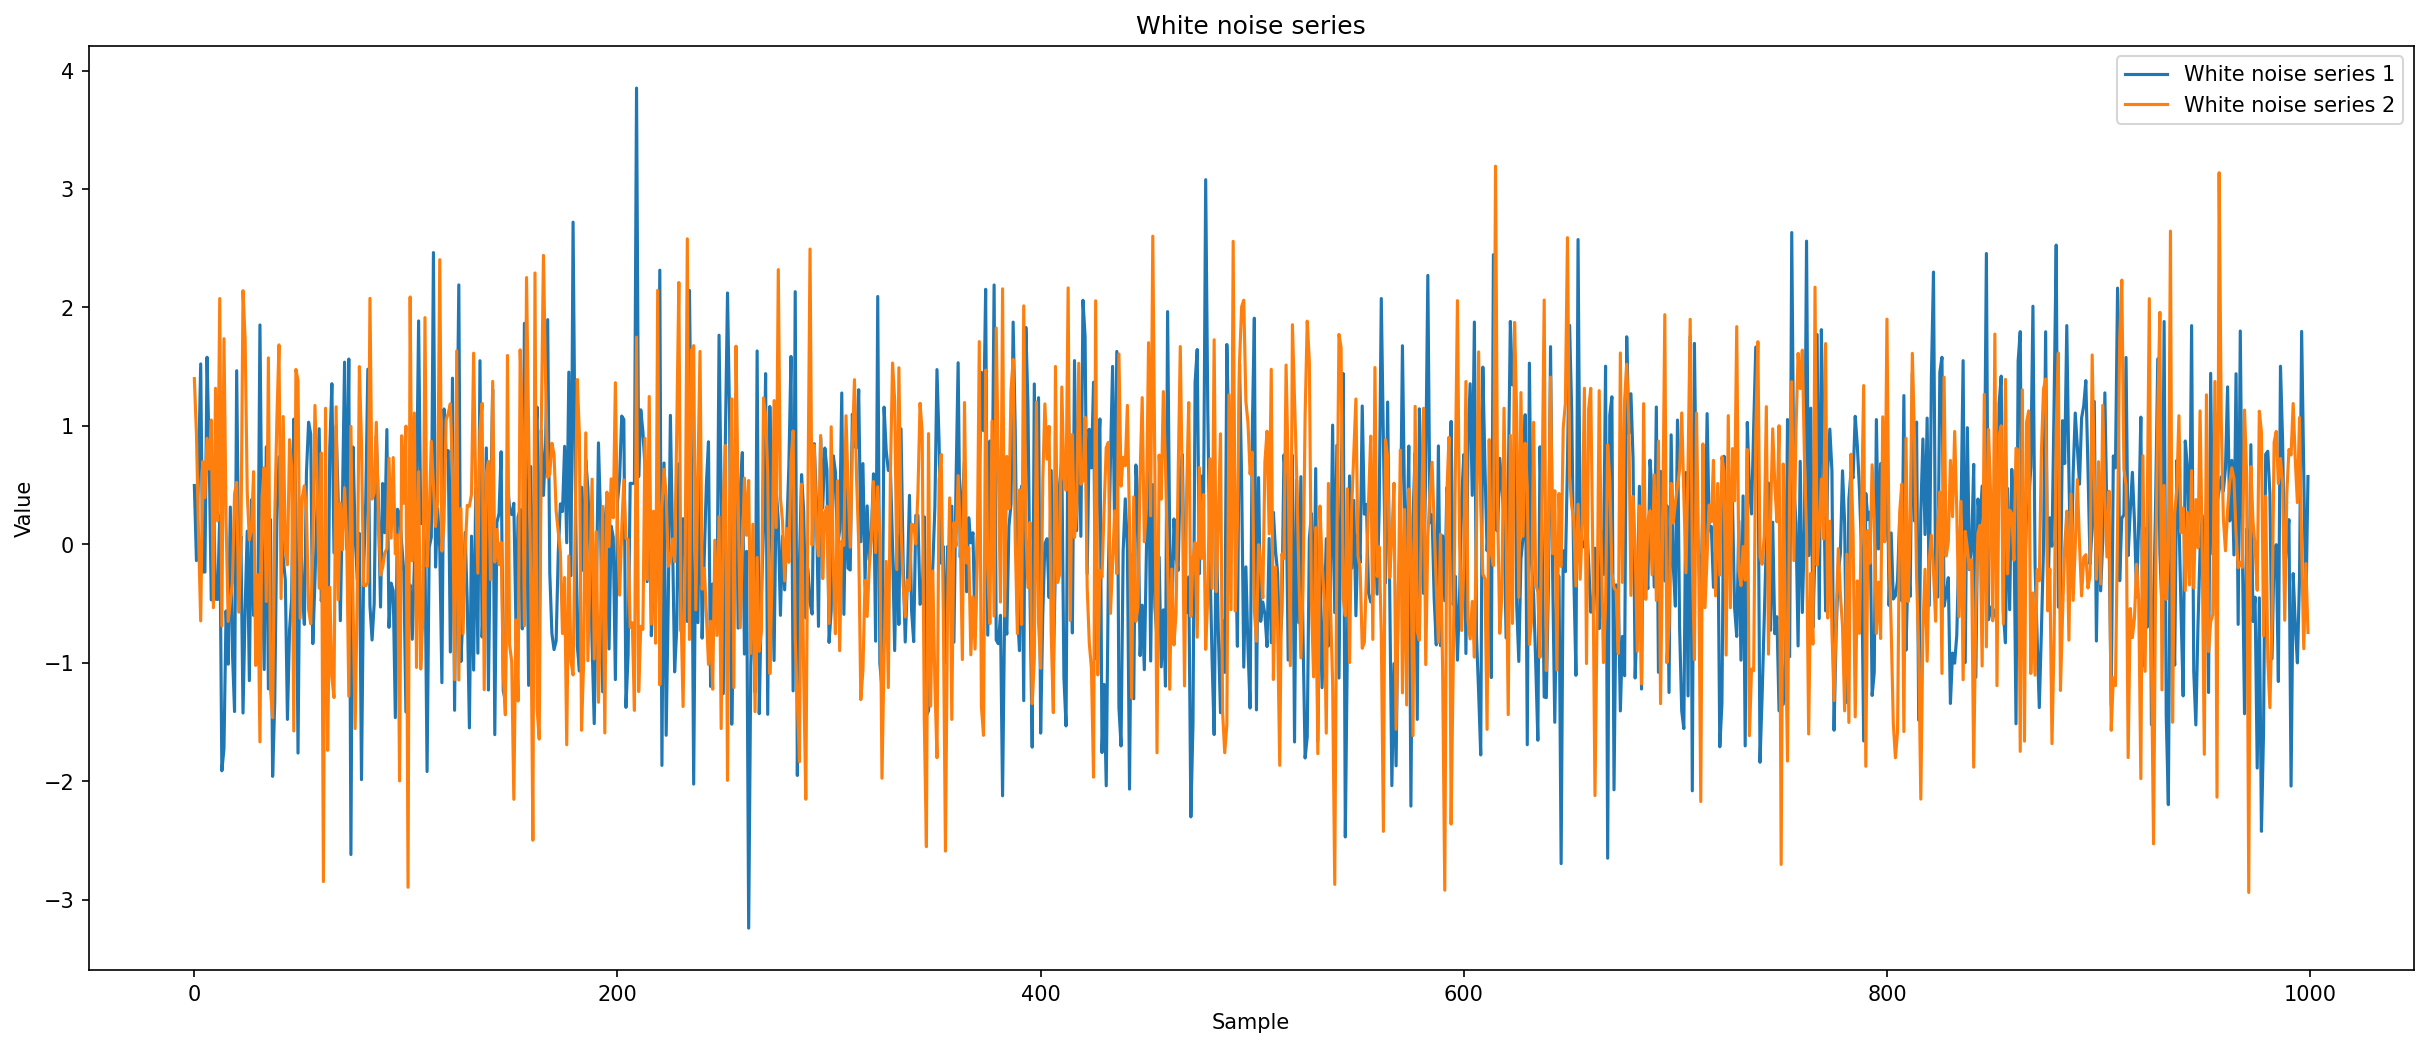

In [ ]:
plt.figure(figsize=(20, 8), dpi=150)

# plot the two white noise series
plt.plot(wn1, label='White noise series 1')
plt.plot(wn2, label='White noise series 2')

# add legend and axis labels
plt.legend()
plt.xlabel('Sample')
plt.ylabel('Value')
plt.title('White noise series')

# show the plot
plt.show()

In [ ]:
# calculate correlation between the two white noise series
corr1 = np.corrcoef(wn1, wn2)[0, 1]
print("Correlation between white noise series: {:.3f}".format(corr1))

Correlation between white noise series: -0.040


In [ ]:
# Now, add a linear trend to both white noise series
trend = np.linspace(0, 10, 1000)
wn1_trend = wn1 + trend
wn2_trend = wn2 + trend

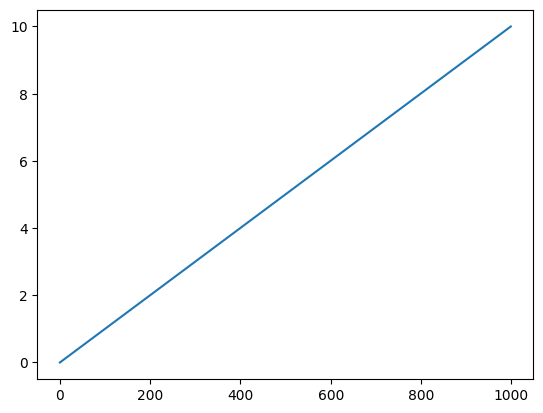

In [ ]:
plt.plot(trend)

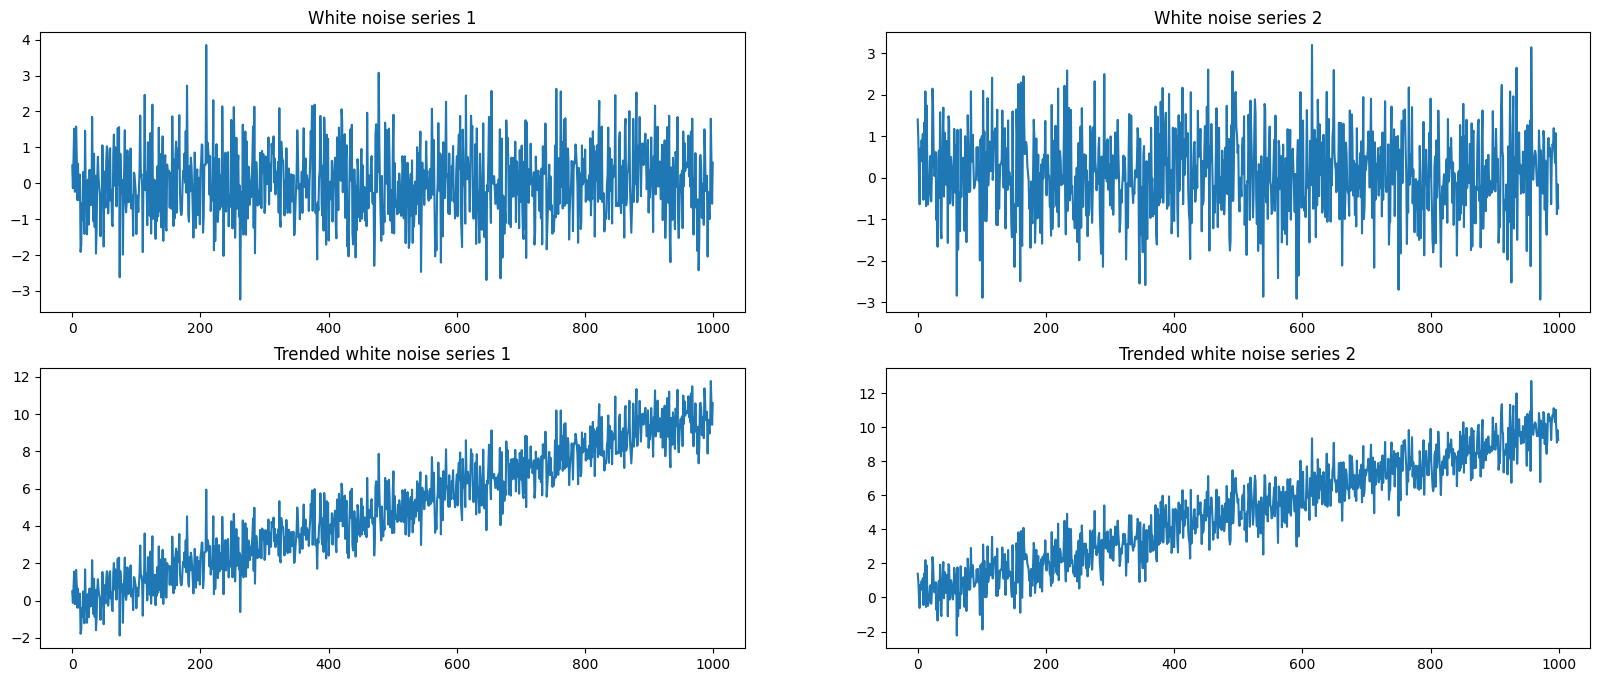

In [ ]:
# plot the white noise series and the trended white noise series
fig, axs = plt.subplots(2, 2, figsize=(20, 8))
axs[0, 0].plot(wn1)
axs[0, 0].set_title("White noise series 1")
axs[0, 1].plot(wn2)
axs[0, 1].set_title("White noise series 2")
axs[1, 0].plot(wn1_trend)
axs[1, 0].set_title("Trended white noise series 1")
axs[1, 1].plot(wn2_trend)
axs[1, 1].set_title("Trended white noise series 2")
plt.show()

In [ ]:
# calculate correlation between the two trended white noise series
corr2 = np.corrcoef(wn1_trend, wn2_trend)[0, 1]
print("Correlation between trended white noise series: {:.3f}".format(corr2))


Correlation between trended white noise series: 0.891


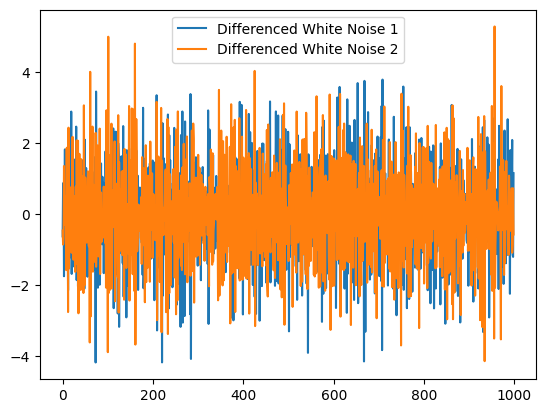

In [ ]:
# Difference the white noise series with trend
diff_1 = np.diff(wn1_trend)
diff_2 = np.diff(wn2_trend)

# Plot the differenced time series
plt.plot(diff_1, label='Differenced White Noise 1')
plt.plot(diff_2, label='Differenced White Noise 2')
plt.legend()
plt.show()

In [ ]:
# Calculate the correlation between the differenced time series
corr_diff = np.corrcoef(diff_1, diff_2)[0, 1]
print(f"The correlation between the differenced time series is {corr_diff}.")

The correlation between the differenced time series is -0.0214771676626417.


In [ ]:
# to escape the spurious correlation trap
# we should difference the time series to detrend it or make it stationary before we check for correlation.

In [ ]:
differenced = df_resample_months.diff()

In [ ]:
differenced

,MSFT_Spline,SPY_Spline
2014-01-01,NaN,NaN
2014-02-01,0.960,-0.095
2014-03-01,1.730,3.245
2014-04-01,0.595,0.245
2014-05-01,0.285,1.565
...,...,...
2026-05-01,7.405,38.270
2026-06-01,-25.440,3.150
2026-07-01,-1.260,5.840
2026-08-01,103.160,22.800


<Axes: >

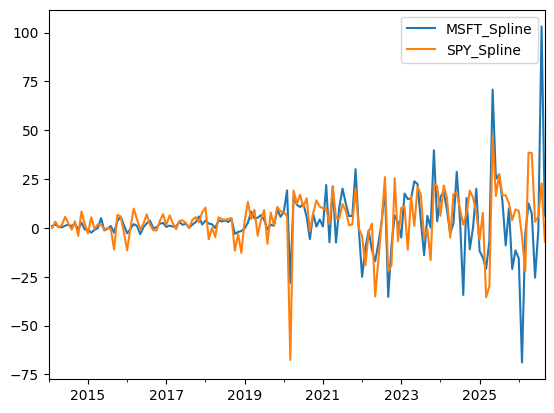

In [ ]:
differenced.plot()

In [ ]:
np.corrcoef(differenced['MSFT_Spline'].dropna(),differenced['SPY_Spline'].dropna())

array([[1.        , 0.55882113],
       [0.55882113, 1.        ]])

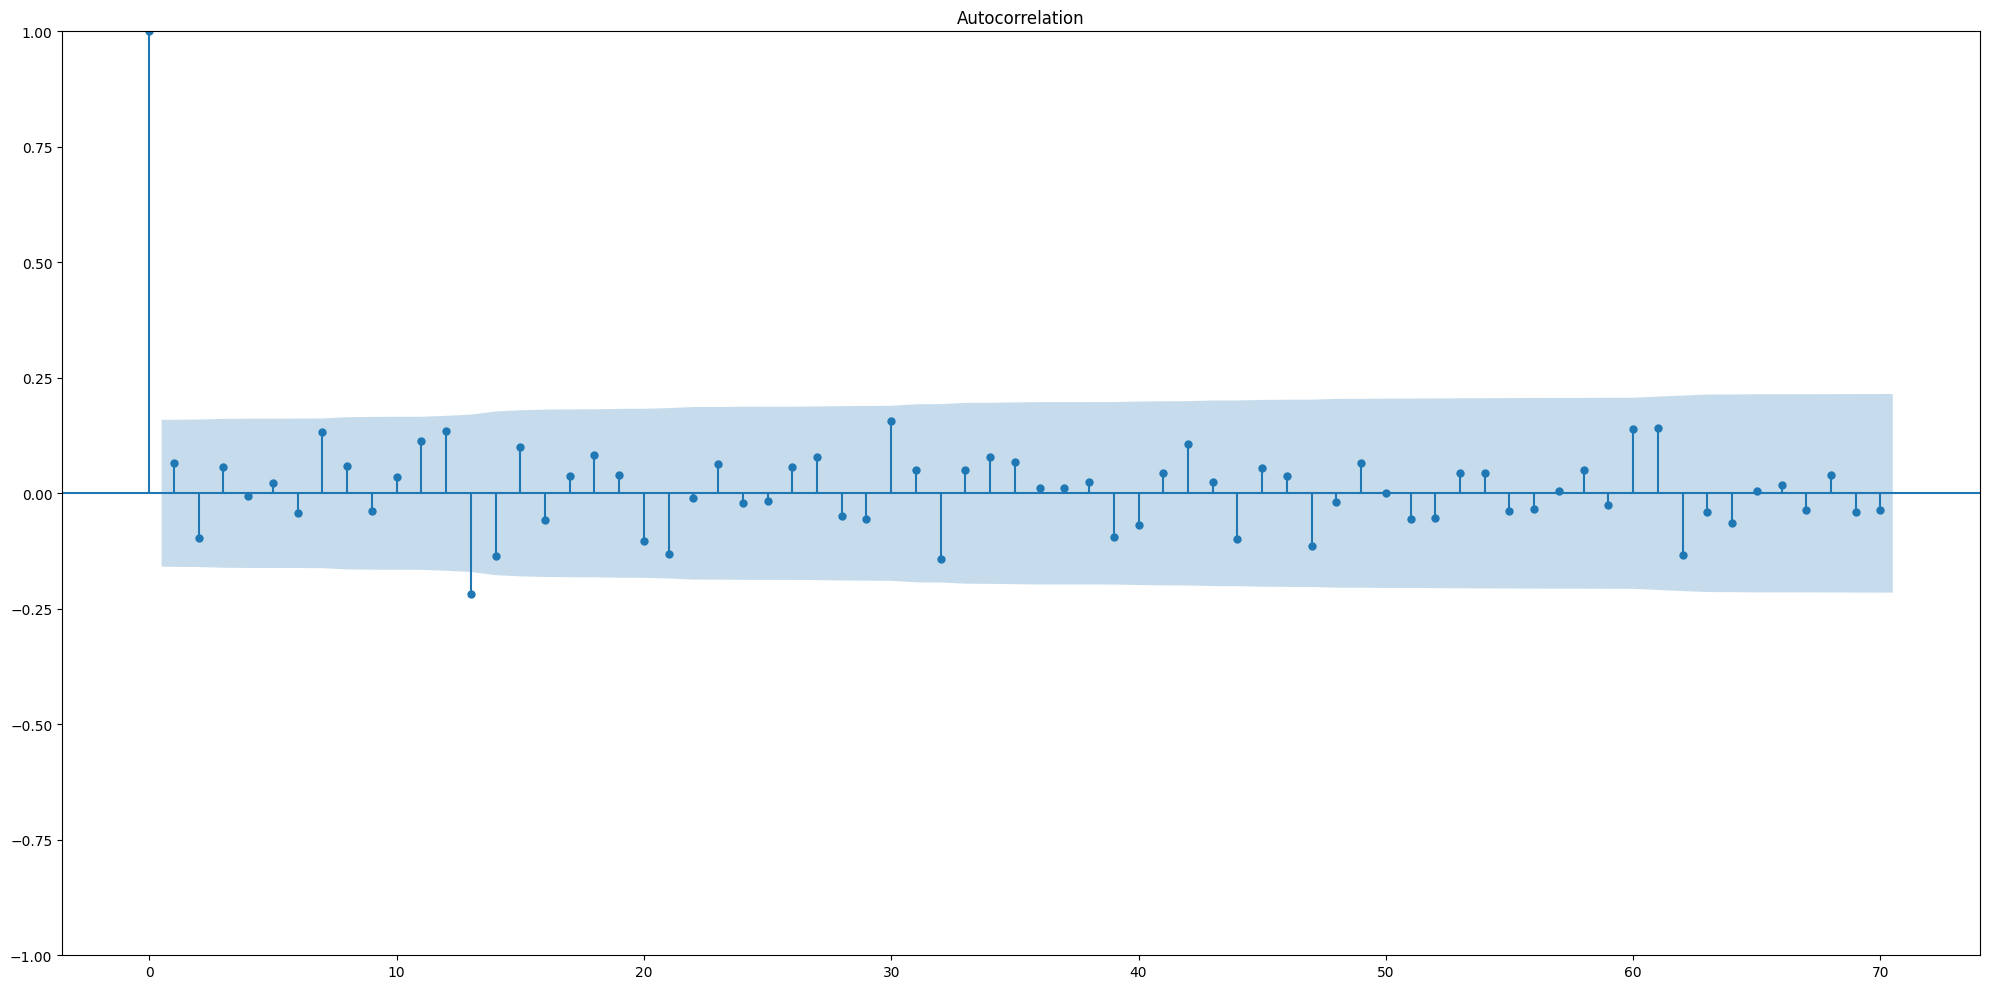

In [ ]:
# Calculate the ACF (via statsmodel)
# Source: https://www.alpharithms.com/autocorrelation-time-series-python-432909/

fig = plot_acf(differenced['SPY_Spline'].dropna(), lags=70)
fig.set_size_inches((20, 10))
# Tight layout to realign things
fig.tight_layout()
plt.show()

## Split data into train and test sets

In [ ]:
# let us select just one series - SPY

In [ ]:
spy = spy_df[['SPY_Spline']]
spy

,SPY_Spline
2014-01-01,148.370
2014-02-01,148.275
2014-03-01,151.520
2014-04-01,151.765
2014-05-01,153.330
...,...
2026-05-01,737.270
2026-06-01,740.420
2026-07-01,746.260
2026-08-01,769.060


In [ ]:
from sklearn.model_selection import train_test_split

# Create a test set of 12 data points
test_size = 12

train_data, test_data = train_test_split(spy, test_size=test_size, random_state=25, shuffle = False)
#shuffle = False is very important to ensure the order of the data

print(f"No. of training examples: {train_data.shape[0]}")
print(f"No. of testing examples: {test_data.shape[0]}")

No. of training examples: 141
No. of testing examples: 12


In [ ]:
train_data

,SPY_Spline
2014-01-01,148.370
2014-02-01,148.275
2014-03-01,151.520
2014-04-01,151.765
2014-05-01,153.330
...,...
2025-05-01,575.000
2025-06-01,591.390
2025-07-01,618.960
2025-08-01,635.650


In [ ]:
test_data

,SPY_Spline
2025-10-01,664.880
2025-11-01,668.875
2025-12-01,678.320
2026-01-01,687.020
2026-02-01,682.740
2026-03-01,660.470
2026-04-01,699.000
2026-05-01,737.270
2026-06-01,740.420
2026-07-01,746.260


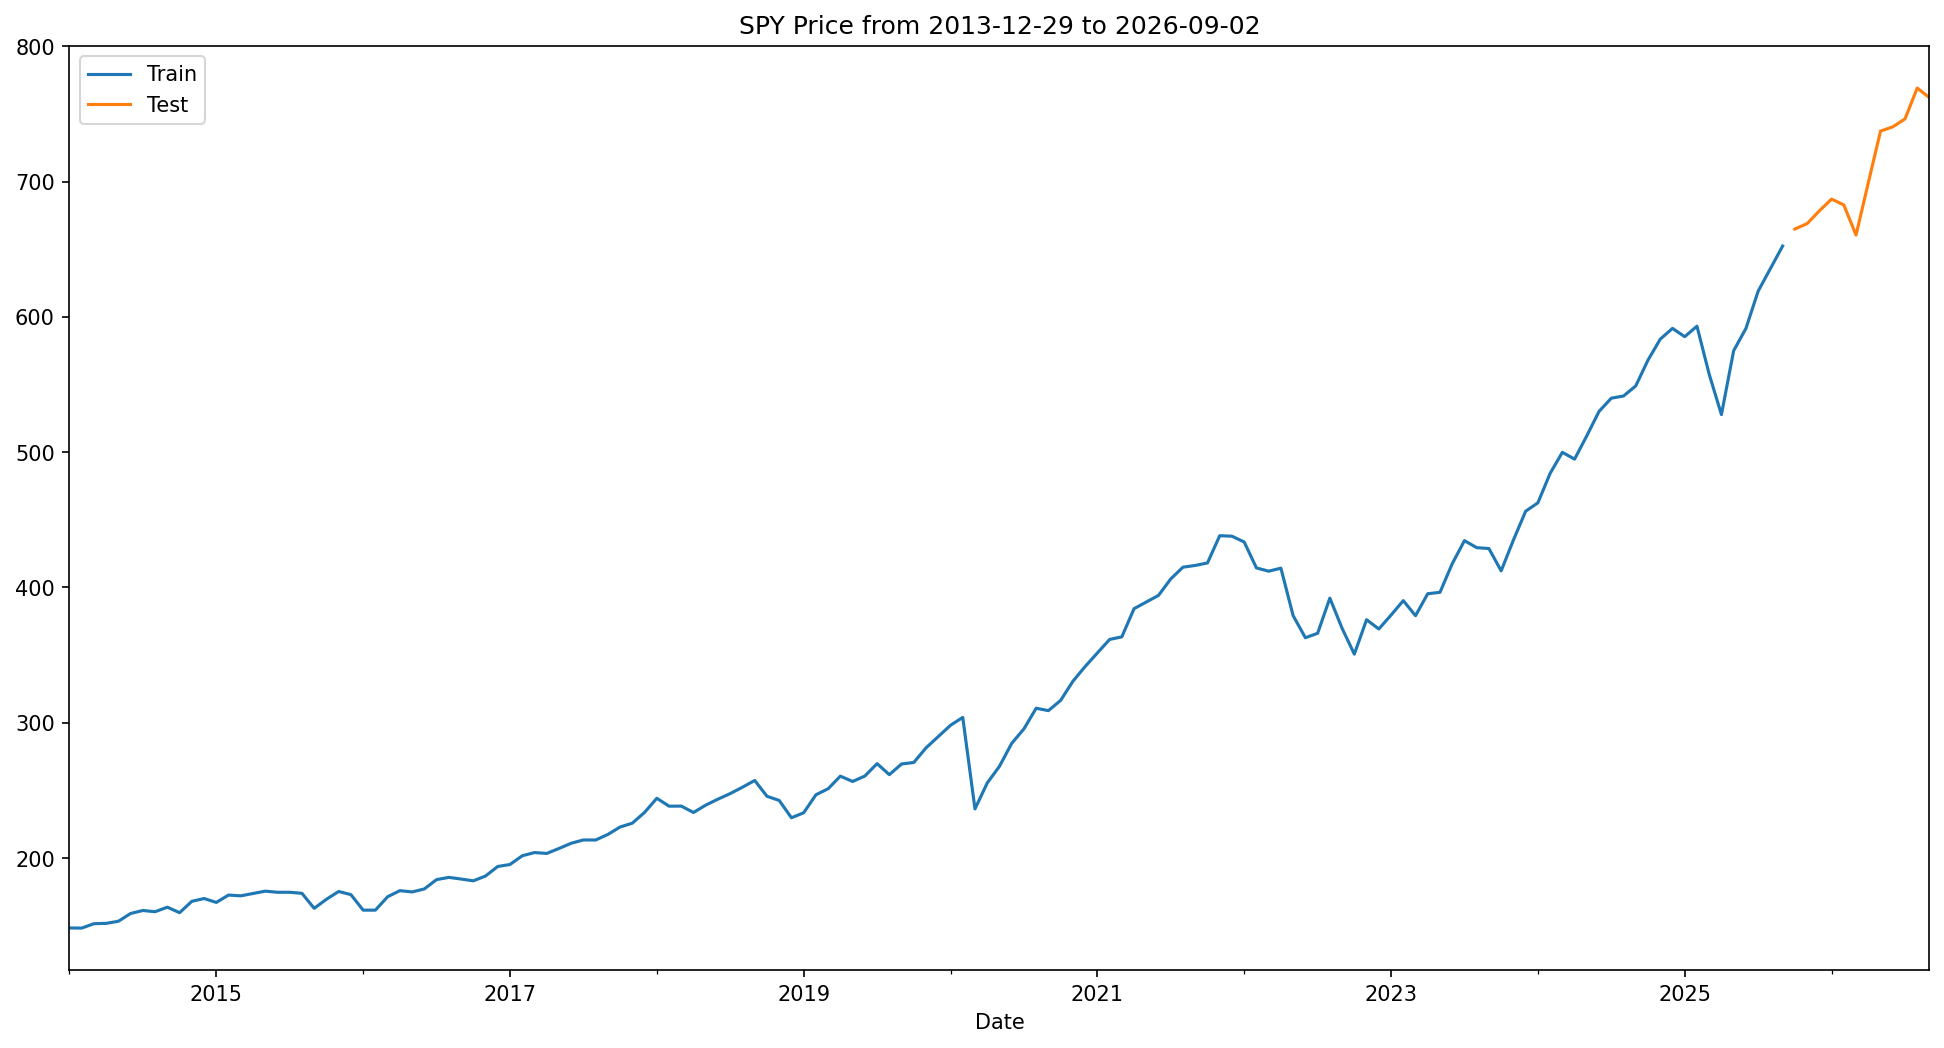

In [ ]:
#Plot train and test data

# to set the plot size
plt.figure(figsize=(16, 8), dpi=150)

# using plot method to plot close prices.
# in plot method we set the label and color of the curve.
train_data['SPY_Spline'].plot(label='Train')
test_data['SPY_Spline'].plot(label='Test')


# adding title to the plot
plt.title('SPY Price from {} to {}'.format(stock_start_date, stock_end_date))

# adding Label to the x-axis
plt.xlabel('Date')

# adding legend to the curve
plt.legend()


## Fitting Models - Exponential Smoothing Models

### ETS - Error, Trend, Seasonailty

Exponential smoothing was proposed in the late 1950s, and has motivated some of the most successful forecasting methods. Exponential smoothing is a time series forecasting method for univariate data. Forecasts produced using exponential smoothing methods are weighted averages of past observations, with the weights decaying exponentially as the observations get older. In other words, the more recent the observation the higher the associated weight.

The weights are controlled by the smoothing parameter which is known as 'alpha'. alpha value can be between 0 to 1:

1. (alpha)=0: Means that forecast for future value is the average of historical data.
2. (alpha)=1: Means that forecast for all future value is the value of the last observation   

Source:
1. https://analyticsindiamag.com/hands-on-guide-to-time-series-analysis-using-simple-exponential-smoothing-in-python/#:~:text=Simple%20Exponential%20Smoothing%20(SES)%20is,statsmodel%20using%20pip%20install%20statsmodel.&text=Simple%20Exponential%20Smoothing%20is%20defined,where%20we%20will%20import%20it.
2. https://machinelearningmastery.com/exponential-smoothing-for-time-series-forecasting-in-python/

#### Simple Exponential Smoothing

The simplest of the exponentially smoothing methods is naturally called simple exponential smoothing (SES). This method is suitable for forecasting data with no clear trend or seasonal pattern.

For creating a prediction model using SES we should have an (alpha) value which can be hyper parameter tuned. Here we will create three instances in which we will take three different (alpha) values as:

1. (alpha) = 0.2
2. (alpha) = 0.5
3. (alpha) value automatically optimized by statsmodel which is the recommended one.

We will pass the data into Simple Exponential Smoothing and fit the data with different values of the Smoothing Level.

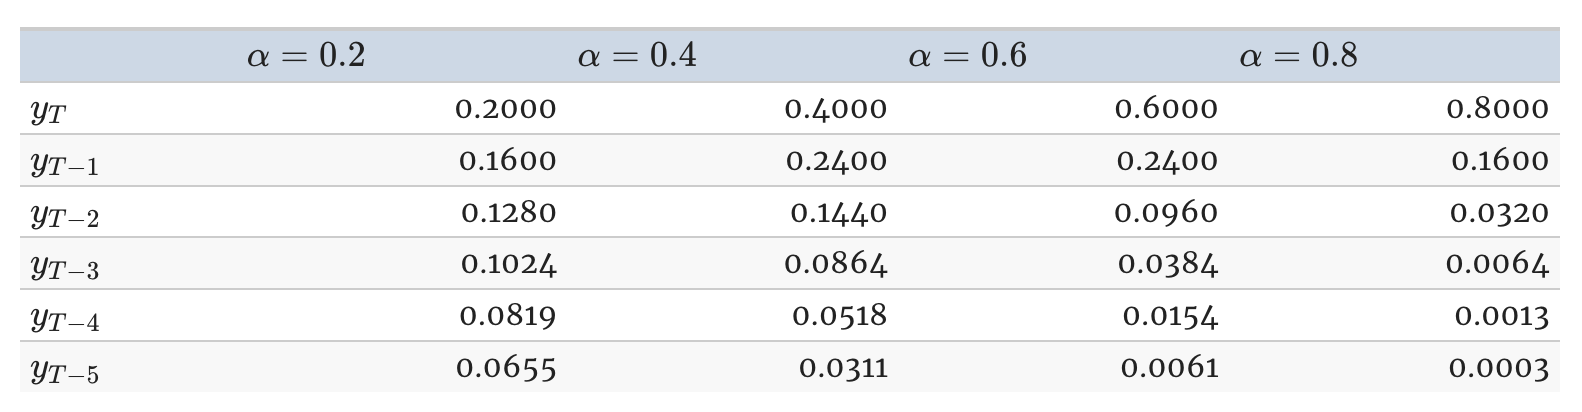

In [ ]:
#First Instance
ins1 = SimpleExpSmoothing(train_data).fit(smoothing_level=0.2,optimized=False)
ins_cast1 = ins1.forecast(12).rename('alpha=0.2')

#Second Instance
ins2 = SimpleExpSmoothing(train_data).fit(smoothing_level=0.5,optimized=False)
ins_cast2 = ins2.forecast(12).rename('alpha=0.5')

#Third Instance
ins3 = SimpleExpSmoothing(train_data).fit()
ins_cast3 = ins3.forecast(12).rename('alpha=%s'%ins3.model.params['smoothing_level'])


In [ ]:
ins_cast1

,alpha=0.2
2025-10-01,600.822513
2025-11-01,600.822513
2025-12-01,600.822513
2026-01-01,600.822513
2026-02-01,600.822513
2026-03-01,600.822513
2026-04-01,600.822513
2026-05-01,600.822513
2026-06-01,600.822513
2026-07-01,600.822513


In [ ]:
test_data

,SPY_Spline
2025-10-01,664.880
2025-11-01,668.875
2025-12-01,678.320
2026-01-01,687.020
2026-02-01,682.740
2026-03-01,660.470
2026-04-01,699.000
2026-05-01,737.270
2026-06-01,740.420
2026-07-01,746.260


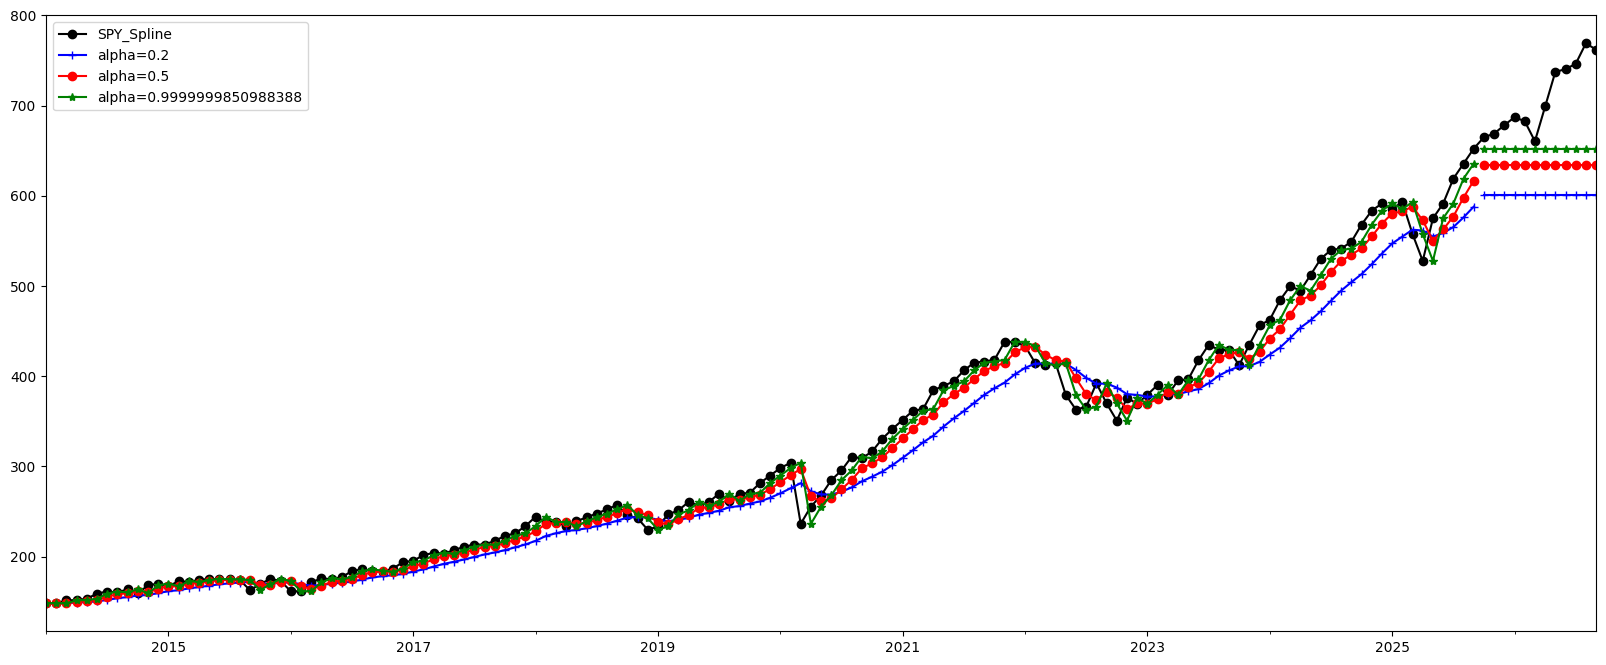

In [ ]:
#After creating model we will visualize the plot
ax = spy.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for alpha =0.2
ins_cast1.plot(marker='+', ax=ax, color='blue', legend=True)
ins1.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for alpha = 0.5
ins_cast2.plot(marker='o', ax=ax, color='red', legend=True)
ins2.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')

plt.show()

In [ ]:
'''
In terms of forecasting, simple exponential smoothing generates a constant set of values.
All forecasts equal the last value of the level component.
Consequently, these forecasts are appropriate only when your time series data have no trend or seasonality.
'''

'\nIn terms of forecasting, simple exponential smoothing generates a constant set of values.\nAll forecasts equal the last value of the level component.\nConsequently, these forecasts are appropriate only when your time series data have no trend or seasonality.\n'

#### Double Exponential Smoothing

This is the extended version of simple exponential smoothing to allow the forecasting of data with a trend. This method has two smoothing equations and hence two parameters, alpha and beta, (one for the level and one for the trend).

In [ ]:
# Double ETS
# Let us fit the data on Double ES, on both Additive and Multiplicative Trend

In [ ]:
double_ets_add = ExponentialSmoothing(train_data, trend = 'add').fit()
double_ets_mul = ExponentialSmoothing(train_data, trend = 'mul').fit()

double_ets_add_pred = double_ets_add.forecast(12)
double_ets_mul_pred = double_ets_mul.forecast(12)


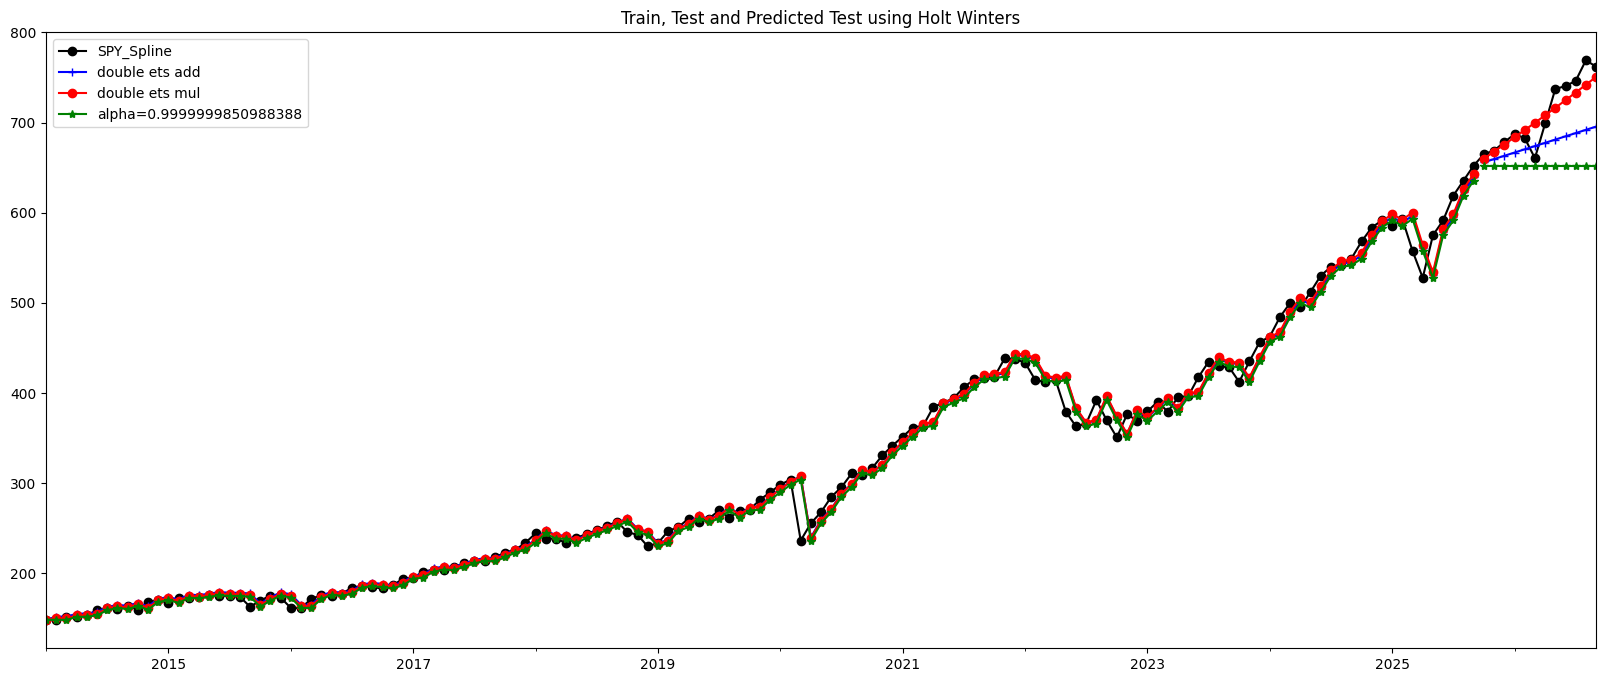

In [ ]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = spy.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
double_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'double ets add')
double_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
double_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'double ets mul')
double_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for simple exponential smooting alpha=Optimized by statsmodel
ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
ins3.fittedvalues.plot(marker='*', ax=ax, color='green')
plt.title('Train, Test and Predicted Test using Holt Winters')
plt.show()



#### Triple Exponential Smoothing

This is the extended version of simple exponential smoothing to allow the forecasting of data with a trend and seasonality. This method has three smoothing equations and hence three parameters - alpha, beta, and gamma. (one each for the level, trend, and seasonality).

In [ ]:
# triple ETS - Holt Winter's Seasonal Method
triple_ets_add = ExponentialSmoothing(train_data, trend = 'add', seasonal = 'add', seasonal_periods=12).fit()
triple_ets_mul = ExponentialSmoothing(train_data, trend = 'mul', seasonal = 'mul', seasonal_periods=12).fit()

triple_ets_add_pred = triple_ets_add.forecast(12)
triple_ets_mul_pred = triple_ets_mul.forecast(12)


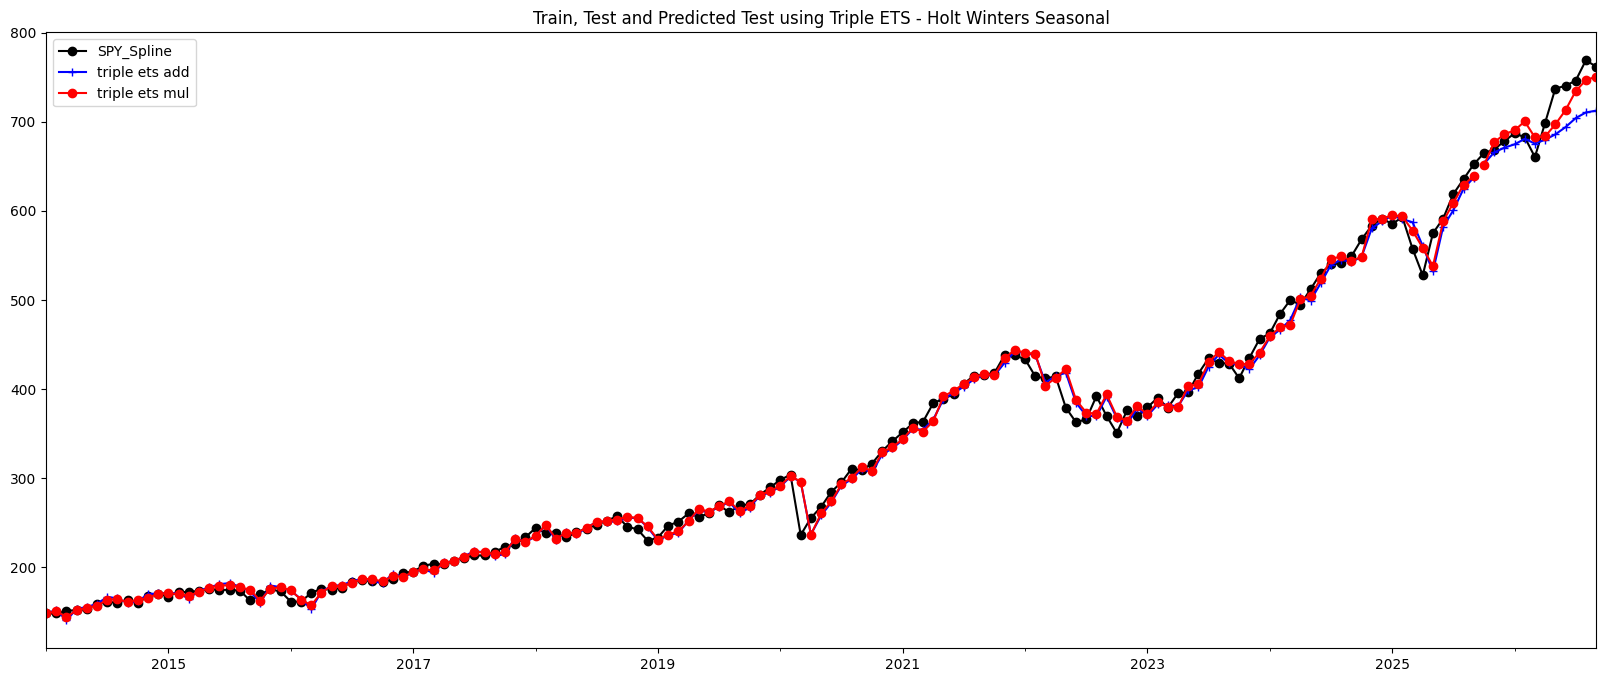

In [ ]:
#plot the train, test, and predictions

#After creating model we will visualize the plot
ax = spy.plot(marker='o', color='black', figsize=(20,8), legend=True)

#Plot for double ETS additive
triple_ets_add_pred.plot(marker='+', ax=ax, color='blue', legend=True, label = 'triple ets add')
triple_ets_add.fittedvalues.plot(marker='+', ax=ax, color='blue')

#Plot for double ETS multiplicative
triple_ets_mul_pred.plot(marker='o', ax=ax, color='red', legend=True, label = 'triple ets mul')
triple_ets_mul.fittedvalues.plot(marker='o', ax=ax, color='red')

#Plot for simple exponential smooting alpha=Optimized by statsmodel
#ins_cast3.plot(marker='*', ax=ax, color='green', legend=True)
#ins3.fittedvalues.plot(marker='*', ax=ax, color='green')
plt.title('Train, Test and Predicted Test using Triple ETS - Holt Winters Seasonal')
plt.show()

## Visualize Forecast Errors

Source: https://machinelearningmastery.com/visualize-time-series-residual-forecast-errors-with-python/

In [ ]:
# Residual Plots / Residual Diagnostics. What are residuals?

In [ ]:
test_data

,SPY_Spline
2025-10-01,664.880
2025-11-01,668.875
2025-12-01,678.320
2026-01-01,687.020
2026-02-01,682.740
2026-03-01,660.470
2026-04-01,699.000
2026-05-01,737.270
2026-06-01,740.420
2026-07-01,746.260


In [ ]:
#calculate residuals
residuals = [test_data.values.flatten()[i]-triple_ets_add_pred.values.flatten()[i] for i in range(len(test_data))]
residuals = pd.DataFrame(residuals)

In [ ]:
residuals

,0
0,12.127373
1,3.236442
2,7.344388
3,12.318262
4,1.919109
5,-15.153253
6,19.118317
7,51.372800
8,46.406806
9,42.095812


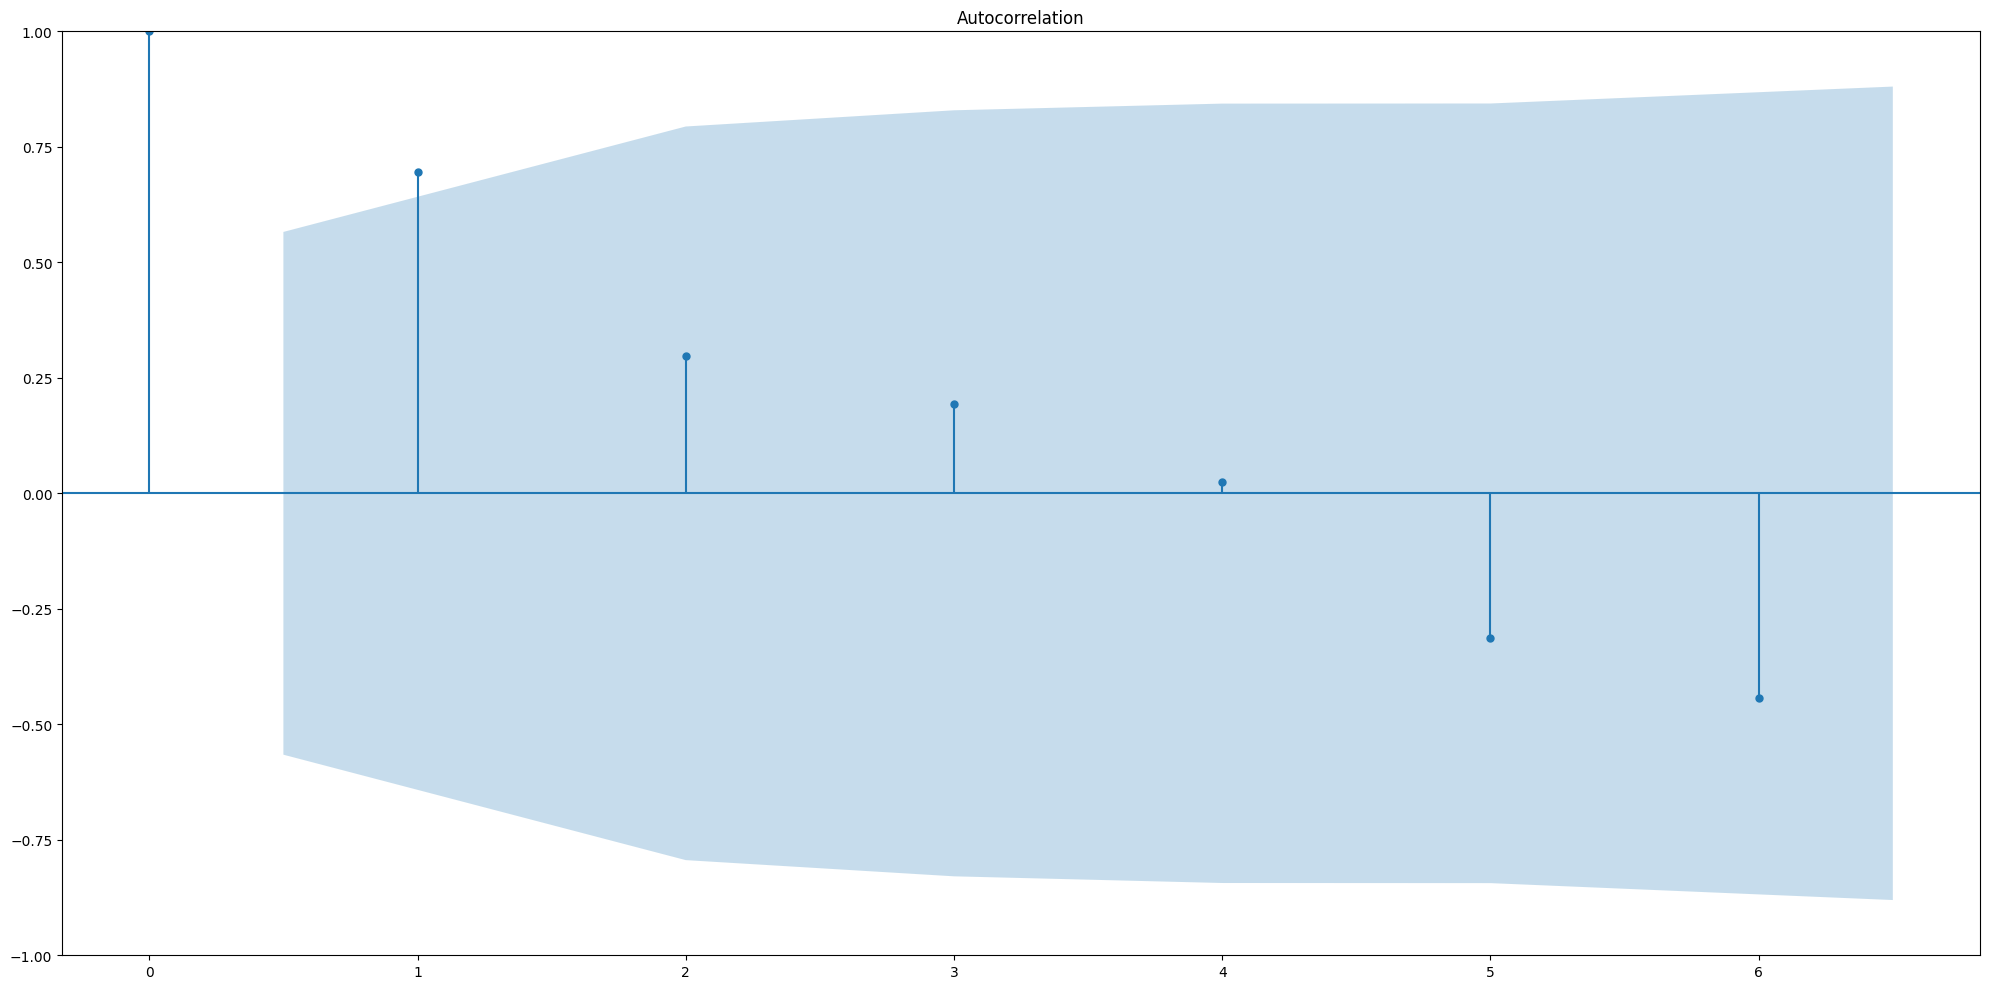

In [ ]:

fig = plot_acf(residuals)
fig.set_size_inches((20, 10))
# Tight layout to realign things
fig.tight_layout()
plt.show()

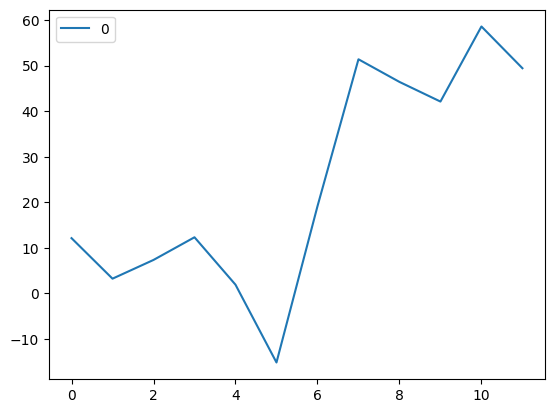

In [ ]:
# plot residuals
residuals.plot()
plt.show()

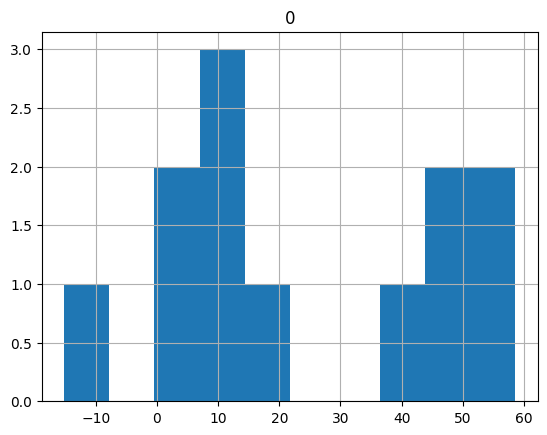

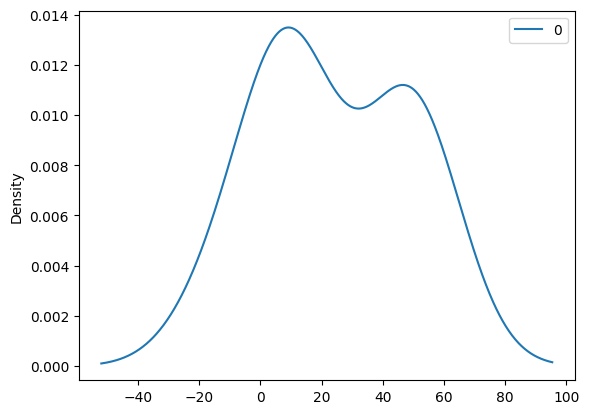

In [ ]:
# histogram plot
residuals.hist()
plt.show()
# density plot
residuals.plot(kind='kde')
plt.show()

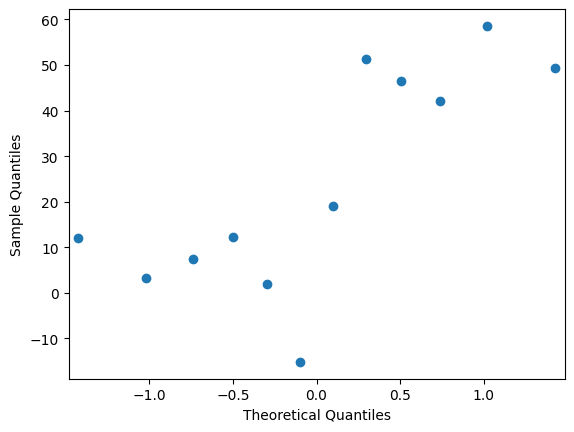

In [ ]:
qqplot(residuals)
plt.show()

### Metrics - model evaluation

1. Root Mean Squared Error (RMSE) represents the sample standard deviation of the differences between predicted values and observed values. These individual differences are called residuals when the calculations are performed over the data sample that was used for estimation, and are called prediction errors when computed out-of-sample. This is a great measurement to use when comparing models as it shows how many deviations from the mean the forecasted values fall.
2. Mean Absolute Error (MAE) takes the sum of the absolute difference from actual to forecast and averages them. It is less sensitive to the occasional very large error because it does not square the errors in the calculation.
3. Mean Absolute Percentage Error (MAPE) is also often useful for purposes of reporting, because it is expressed in generic percentage terms it will make sense even to someone who has no idea what constitutes a "big" error in terms of dollars spent or widgets sold.

In [ ]:
#define metrics dataframe which will be used below for storing results
metrics_dataframe = pd.DataFrame(columns=['Model', 'RMSE', 'MAE', 'MAPE'])

def metrics_cal(actuals, predictions, model):
    mse = mean_squared_error(actuals, predictions)
    rmse = sqrt(mse)
    mae = mean_absolute_error(actuals, predictions)
    mape = np.mean(np.abs((actuals - predictions) / actuals)) * 100

    df = pd.DataFrame({'Model': [model],
                       'RMSE': [rmse],
                       'MAE': [mae],
                       'MAPE': [mape]})

    global metrics_dataframe
    metrics_dataframe = pd.concat([metrics_dataframe, df], ignore_index=True)
    return metrics_dataframe

In [ ]:
#get all the metrics
metrics_dataframe = metrics_cal(test_data.values.flatten(),
                                ins_cast1.values.flatten(),
                                'Simple 0.2')

metrics_dataframe = metrics_cal(test_data.values.flatten(),
                                ins_cast2.values.flatten(),
                                'Simple 0.5')

metrics_dataframe = metrics_cal(test_data.values.flatten(),
                                ins_cast3.values.flatten(),
                                'Simple 1')

metrics_dataframe = metrics_cal(test_data.values.flatten(),
                                double_ets_add_pred.values.flatten(),
                                'Double Add')

metrics_dataframe = metrics_cal(test_data.values.flatten(),
                                double_ets_mul_pred.values.flatten(),
                                'Double Mul')


metrics_dataframe = metrics_cal(test_data.values.flatten(),
                                triple_ets_add_pred.values.flatten(),
                                'Triple Add')

metrics_dataframe = metrics_cal(test_data.values.flatten(),
                                triple_ets_mul_pred.values.flatten(),
                                'Triple Mul')


/tmp/ipykernel_3270/2243136297.py:16: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  metrics_dataframe = pd.concat([metrics_dataframe, df], ignore_index=True)


In [ ]:
metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
4,Double Mul,16.983662,13.106060,1.836398
6,Triple Mul,19.332974,16.733348,2.343022
5,Triple Add,33.414949,26.589415,3.622579
3,Double Add,42.431287,34.564817,4.713062
2,Simple 1,67.677952,55.723750,7.602372
1,Simple 0.5,82.898978,73.464765,10.115368
0,Simple 0.2,113.873940,107.201237,14.894105


In [ ]:
spy.tail(12).mean()


,0
SPY_Spline,708.02375


In [ ]:
triple_ets_add_pred.values.flatten()

array([652.75262659, 665.63855832, 670.97561163, 674.70173788,
       680.82089082, 675.62325278, 679.88168327, 685.89720008,
       694.01319406, 704.16418782, 710.48910827, 712.56047305])

In [ ]:
# Create a data frame with all the predictions along with the test data
test_pred_df = test_data.copy()

# Add all predictions
test_pred_df = test_pred_df.assign(triple_ets_mul_pred = triple_ets_mul_pred.values.flatten(),
                                   SimpleExp_1_pred = ins_cast3.values.flatten(),
                                   double_ets_mul_pred = double_ets_mul_pred.values.flatten())

test_pred_df

,SPY_Spline,triple_ets_mul_pred,SimpleExp_1_pred,double_ets_mul_pred
2025-10-01,664.880,651.253724,652.3,659.981123
2025-11-01,668.875,676.877418,652.3,667.752694
2025-12-01,678.320,686.091633,652.3,675.615780
2026-01-01,687.020,690.370011,652.3,683.571456
2026-02-01,682.740,700.459244,652.3,691.620815
2026-03-01,660.470,682.486259,652.3,699.764958
2026-04-01,699.000,683.646421,652.3,708.005002
2026-05-01,737.270,697.072159,652.3,716.342076
2026-06-01,740.420,713.018497,652.3,724.777323
2026-07-01,746.260,734.473191,652.3,733.311898


In [ ]:
# Create an average prediction from the three and check it's metrics
test_pred_df['Average_Predictions'] = (test_pred_df['SimpleExp_1_pred']+test_pred_df['triple_ets_mul_pred']+test_pred_df['double_ets_mul_pred'])/3
test_pred_df


,SPY_Spline,triple_ets_mul_pred,SimpleExp_1_pred,double_ets_mul_pred,Average_Predictions
2025-10-01,664.880,651.253724,652.3,659.981123,654.511615
2025-11-01,668.875,676.877418,652.3,667.752694,665.643371
2025-12-01,678.320,686.091633,652.3,675.615780,671.335804
2026-01-01,687.020,690.370011,652.3,683.571456,675.413822
2026-02-01,682.740,700.459244,652.3,691.620815,681.460019
2026-03-01,660.470,682.486259,652.3,699.764958,678.183739
2026-04-01,699.000,683.646421,652.3,708.005002,681.317141
2026-05-01,737.270,697.072159,652.3,716.342076,688.571412
2026-06-01,740.420,713.018497,652.3,724.777323,696.698607
2026-07-01,746.260,734.473191,652.3,733.311898,706.695030


In [ ]:
metrics_dataframe = metrics_cal(test_data.values.flatten(),
                                test_pred_df['Average_Predictions'].values.flatten(),
                                'Average')

metrics_dataframe.sort_values(by='MAE')

,Model,RMSE,MAE,MAPE
4,Double Mul,16.983662,13.106060,1.836398
6,Triple Mul,19.332974,16.733348,2.343022
7,Average,31.343198,25.026657,3.413315
5,Triple Add,33.414949,26.589415,3.622579
3,Double Add,42.431287,34.564817,4.713062
2,Simple 1,67.677952,55.723750,7.602372
1,Simple 0.5,82.898978,73.464765,10.115368
0,Simple 0.2,113.873940,107.201237,14.894105


In [ ]:
# write data to csv and excel
#test_pred_df.to_csv('/Users/shaikht1/Downloads/test.csv', index = True, header=True)
#test_pred_df.to_excel('/Users/shaikht1/Downloads/test.xlsx', index = True, header=True)